In [25]:
# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
%matplotlib inline

def set_rho(ff):
    rho_fat = np.array(0.9)
    rho_water = np.array((rho_fat*((1-ff)/ff)))
    return (rho_fat,rho_water)

def discrete_timeseries(n_echoes):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: n_echoes     -> integer >0, number of equally spaced echoes
    returns:    echo_times
     '''
    
    #TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    
    return echo_times


def gen_GRE(echo_times, rho_fat, rho_water):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs (absolute signal intensity) (equivalent to ydata)
    '''
    rho = np.array([rho_fat*0.047,\
    rho_fat*0.039,\
    rho_fat*0.006,\
    rho_fat*0.12,\
    rho_fat*0.7,\
    rho_fat*0.088,\
    rho_water]) #rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    
    #standard, individual T2* values
    t2star = np.array([0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] )
    
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0)      #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(Sabs)
    return (Sabs)


def continuous_timeseries(endpoint=0.01):
    return np.linspace(0, endpoint, 1000, endpoint=True)

def calc_fatfrac(fitted_parameters):
    ff =  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])
    return ff

## colocando erros não aleatórios nos valores iniciais

## variando o valor inicial da gordura (relativo)

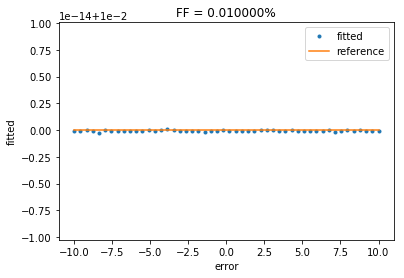

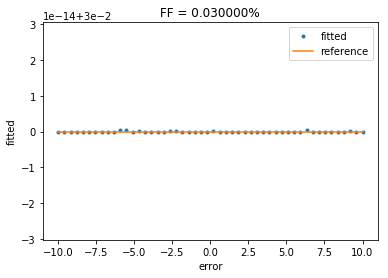

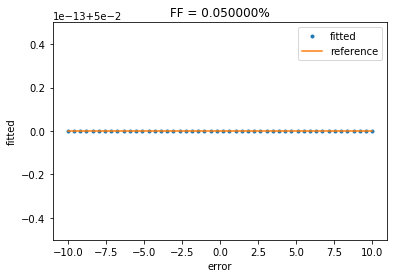

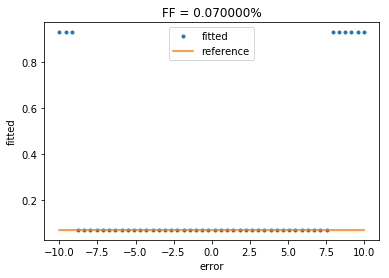

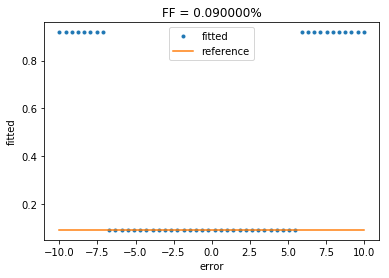

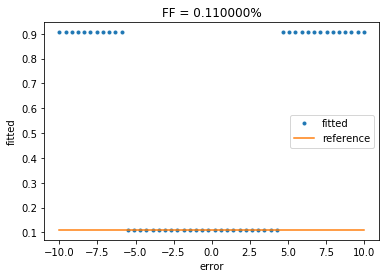

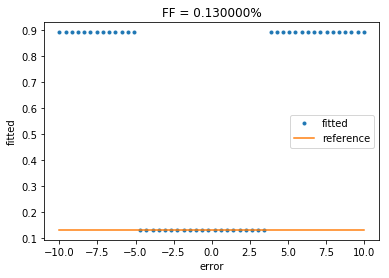

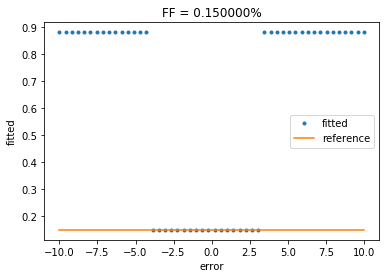

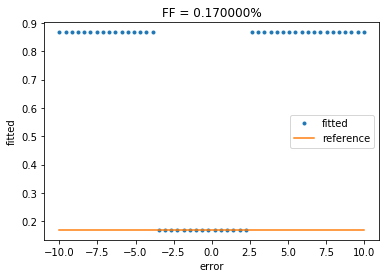

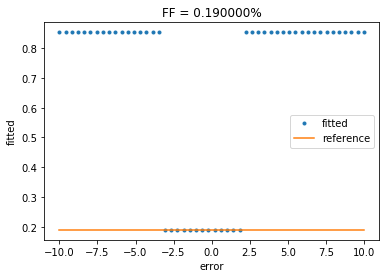

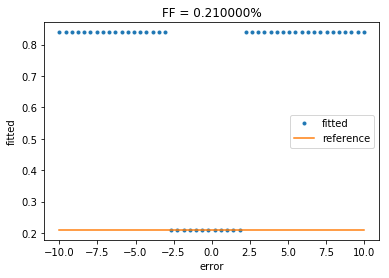

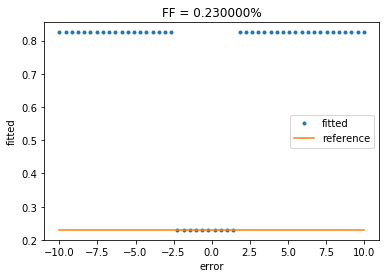

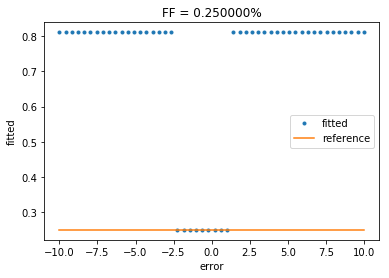

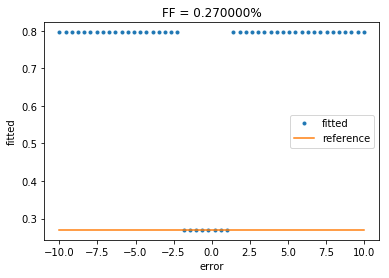

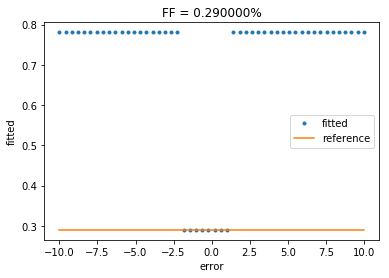

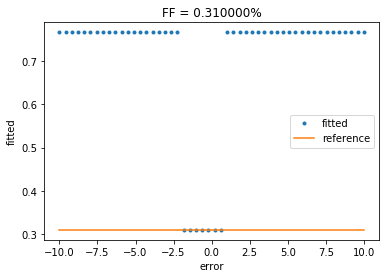

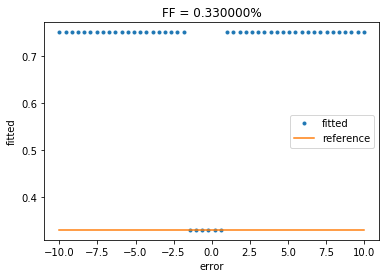

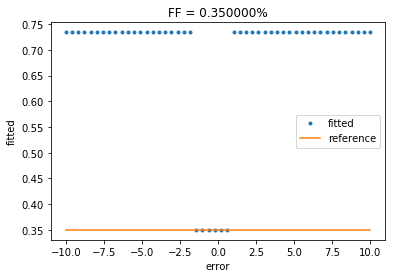

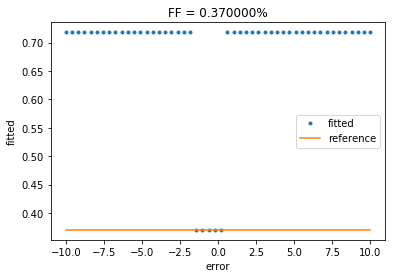

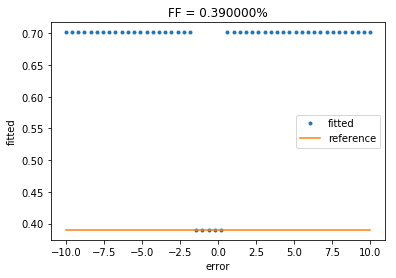

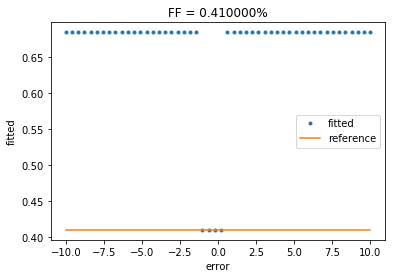

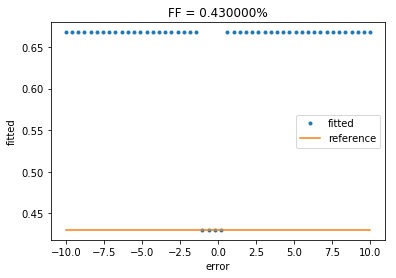

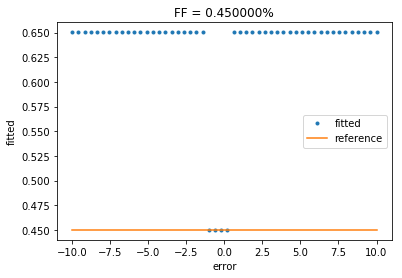

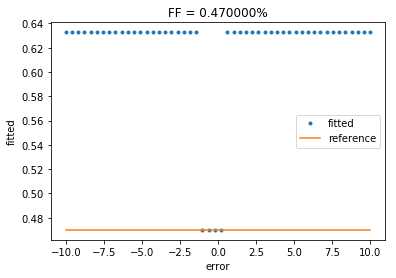

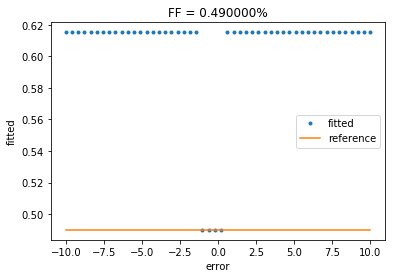

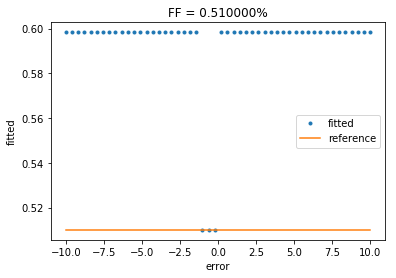

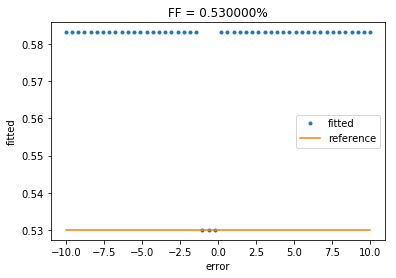

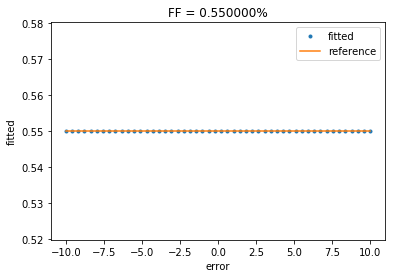

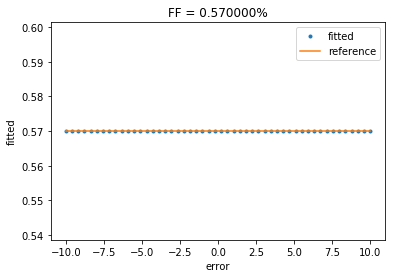

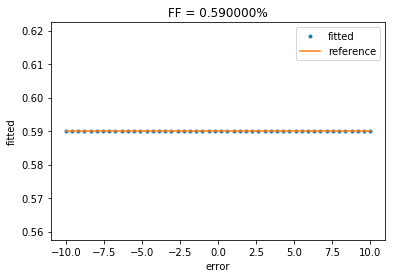

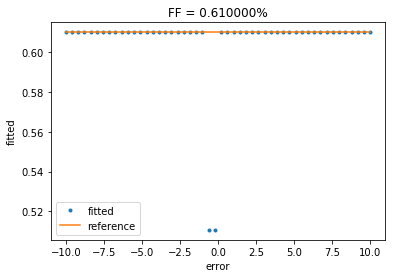

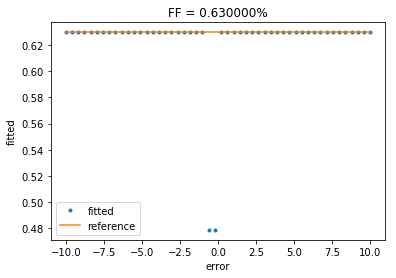

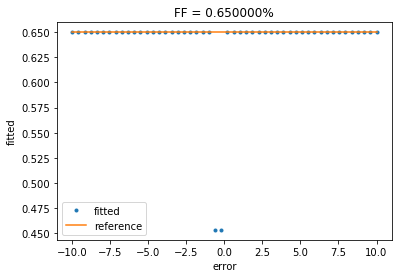

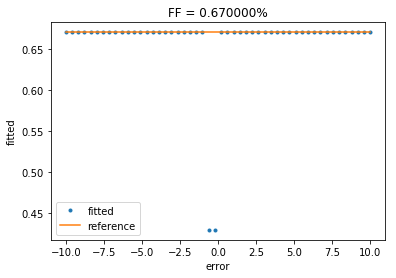

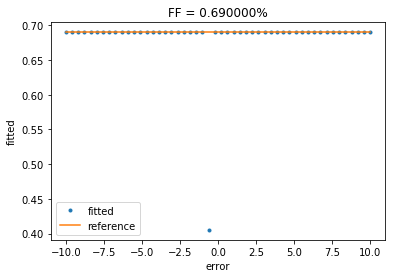

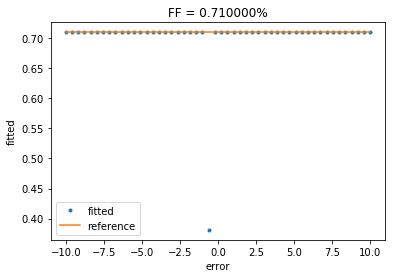

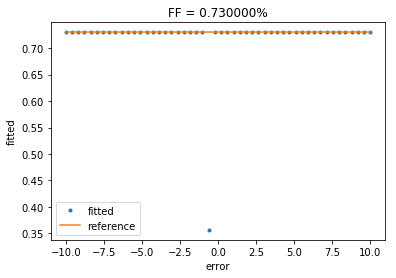

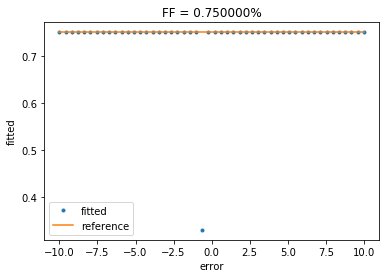

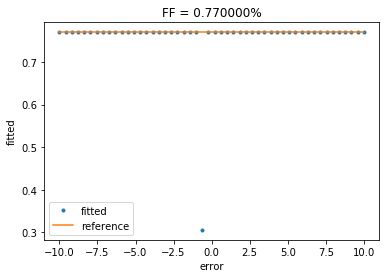

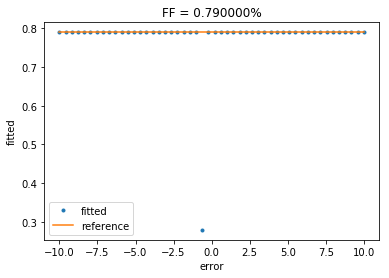

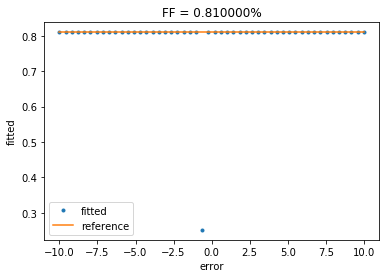

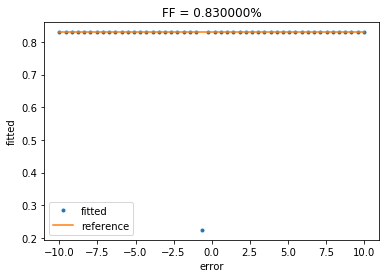

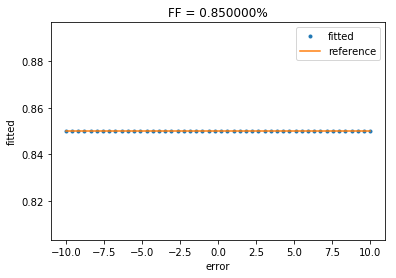

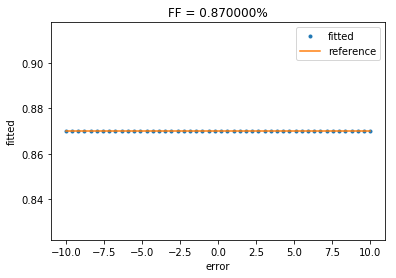

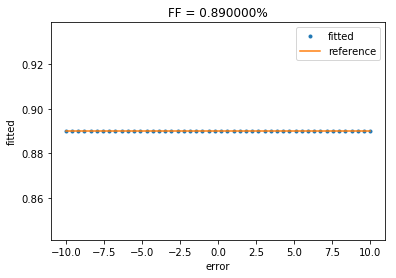

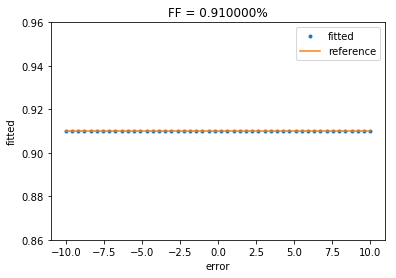

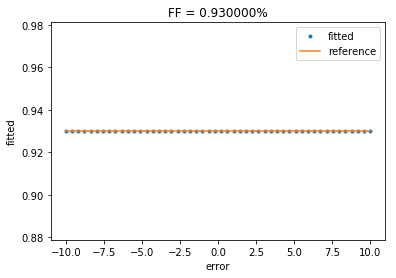

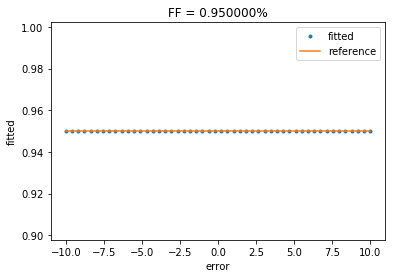

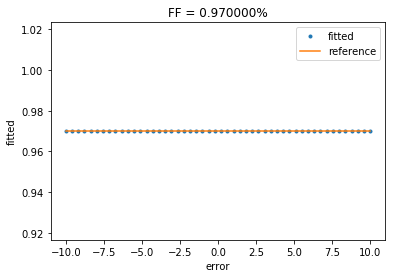

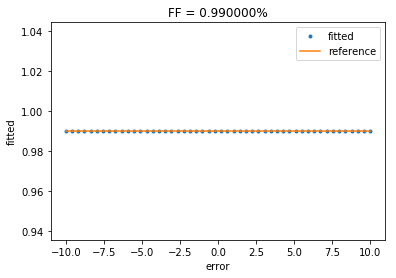

In [62]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.99)   # fat fraction
error = np.linspace(-10,10)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    fitted1 = []
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))
    
    ref = np.zeros(np.size(fitted1))+n #original FF
    
    plt.figure()
    plt.title('FF = %f%%' % n)
    plt.xlabel('error')
    plt.ylabel('fitted')
    plt.plot(error, fitted1,'.', label='fitted')
    plt.plot(error, ref, label='reference')
    plt.legend()
    plt.show
    

# Variando o valor inicial da agua (relativo)

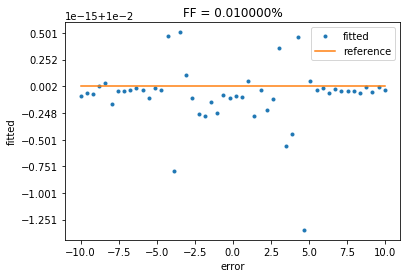

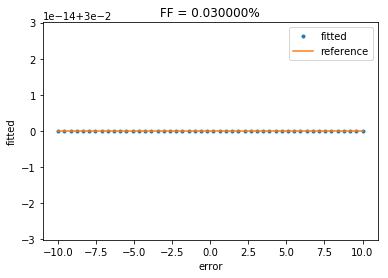

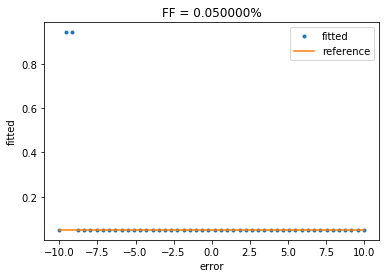

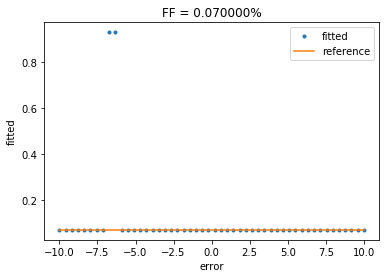

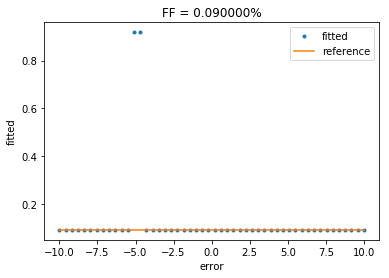

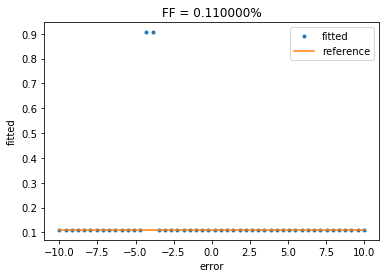

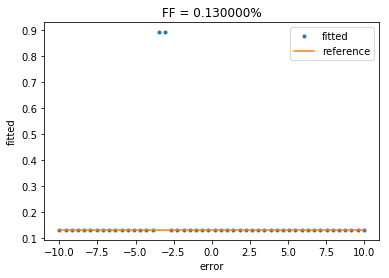

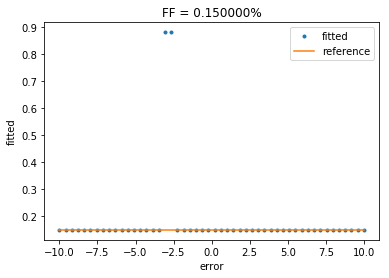

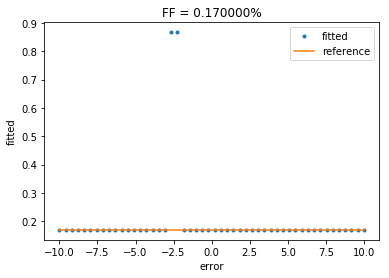

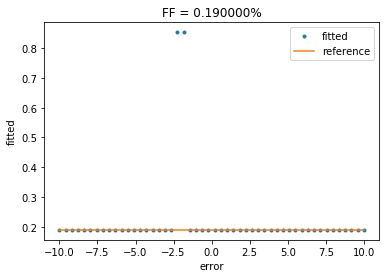

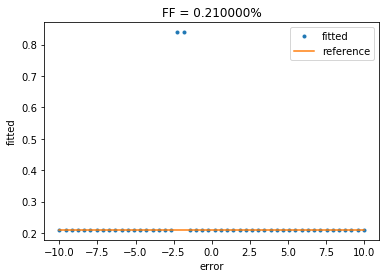

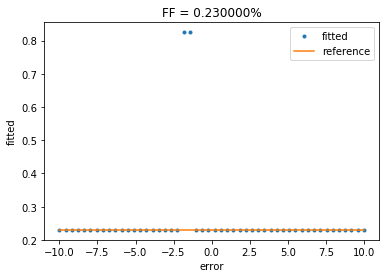

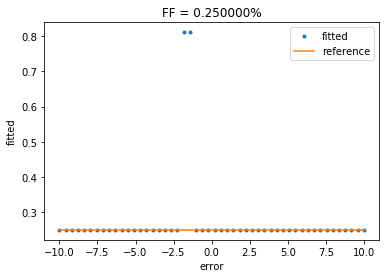

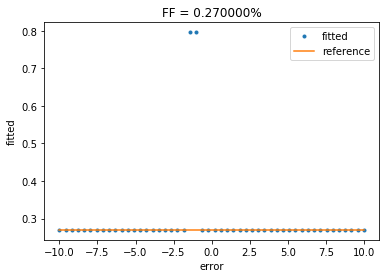

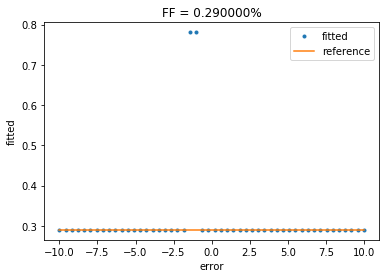

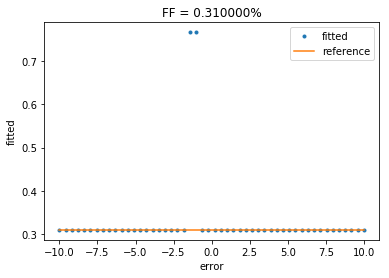

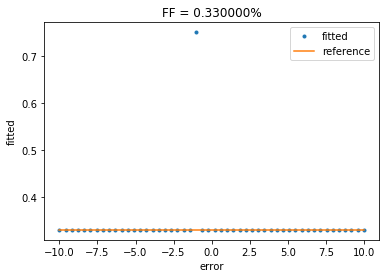

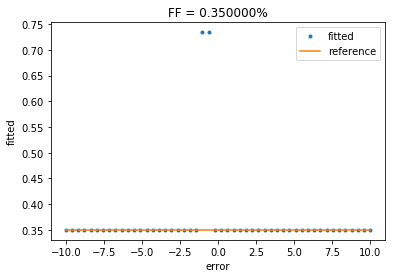

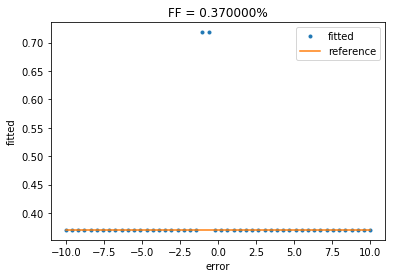

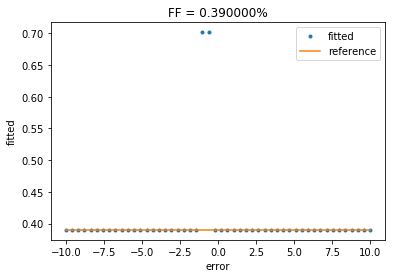

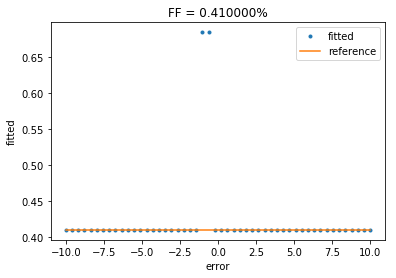

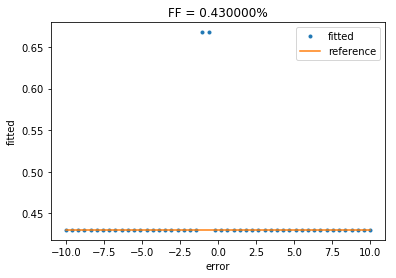

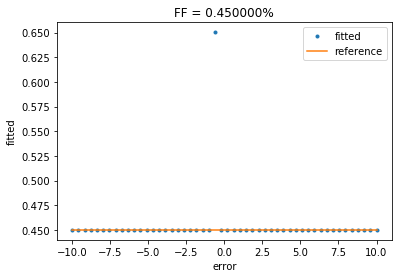

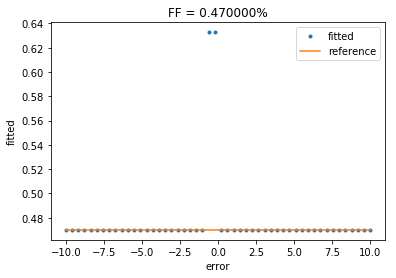

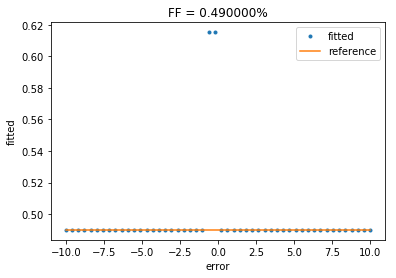

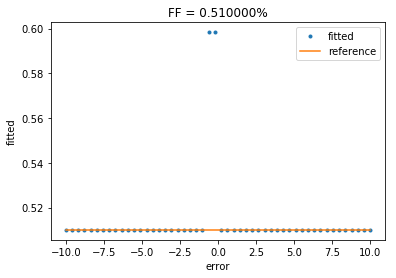

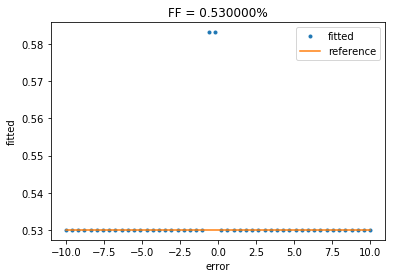

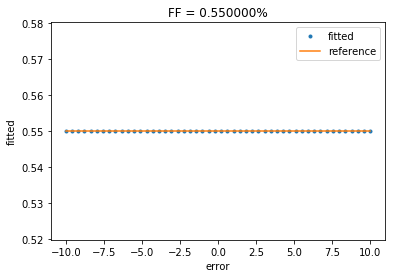

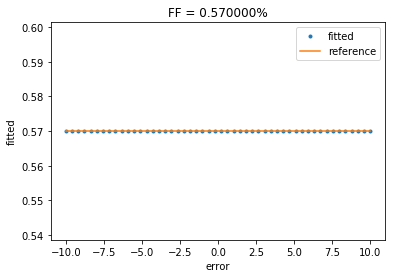

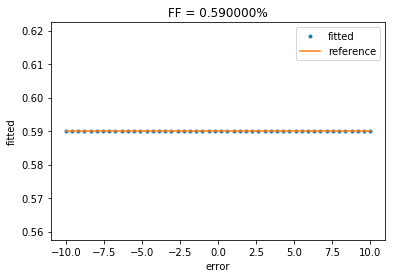

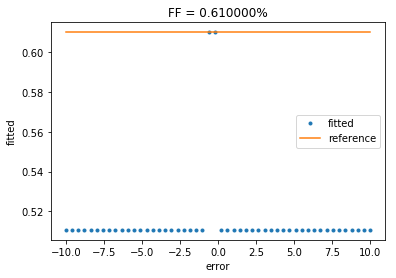

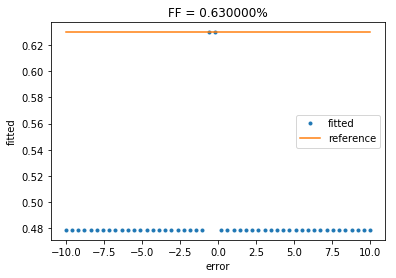

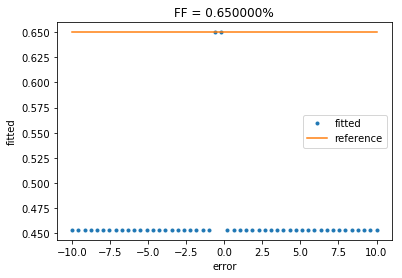

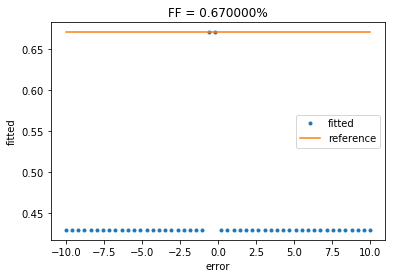

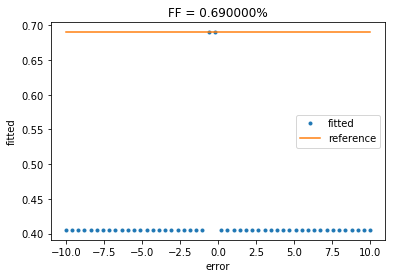

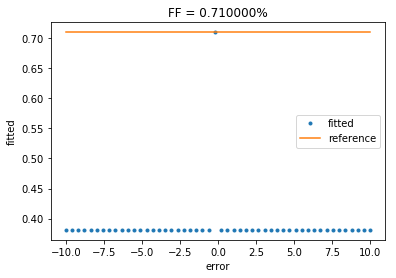

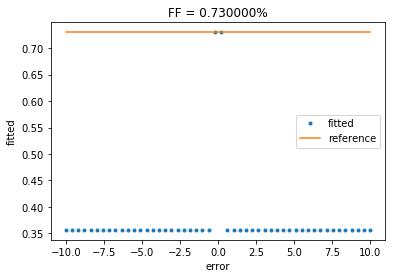

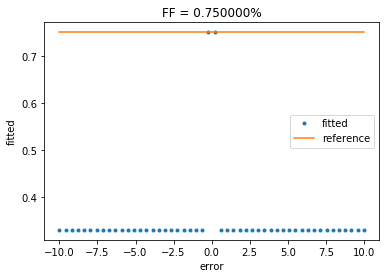

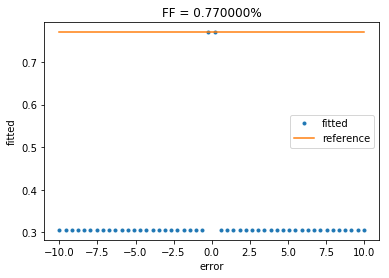

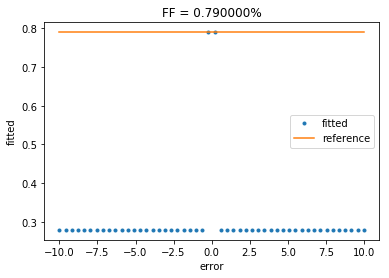

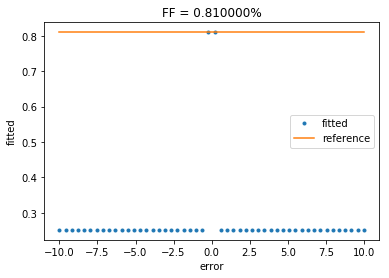

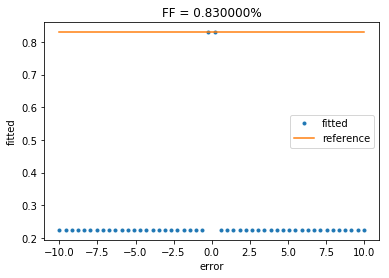

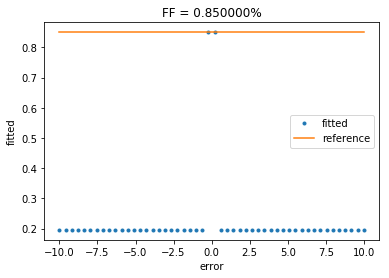

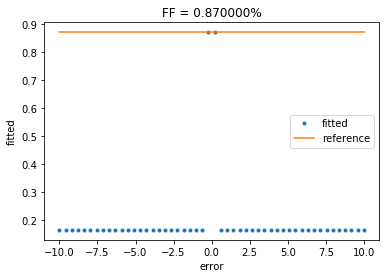

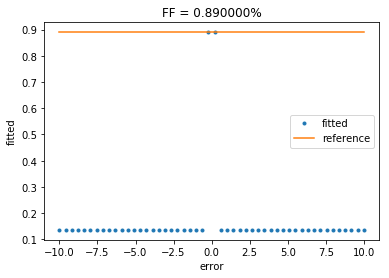

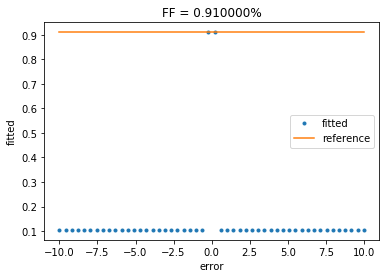

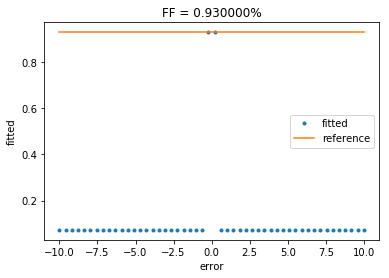

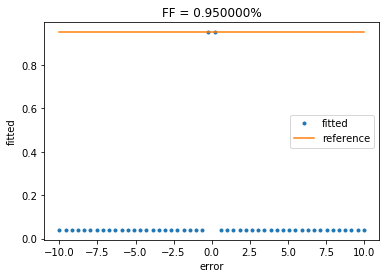

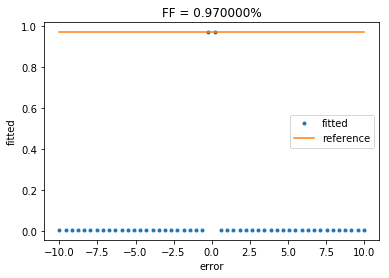

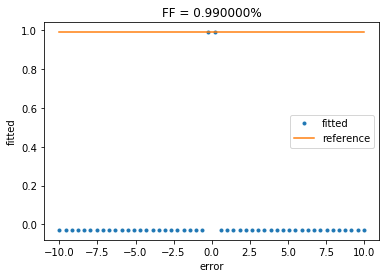

In [63]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.99)   # fat fraction
error = np.linspace(-10,10)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    fitted1 = []
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat, rho_water+erro] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))
    
    ref = np.zeros(np.size(fitted1))+n #original FF
    
    plt.figure()
    plt.title('FF = %f%%' % n)
    plt.xlabel('error')
    plt.ylabel('fitted')
    plt.plot(error, fitted1,'.', label='fitted')
    plt.plot(error, ref, label='reference')
    plt.legend()
    plt.show
    

# Variando o valor inicial da agua e gordura (relativo)

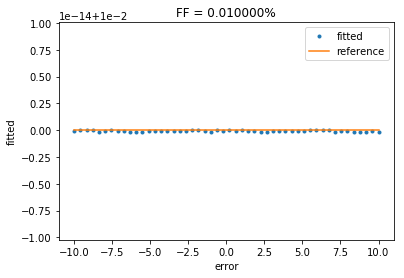

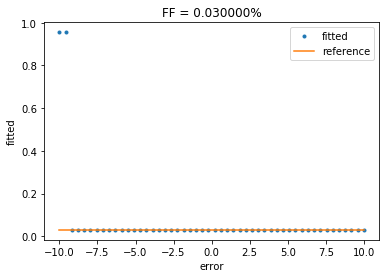

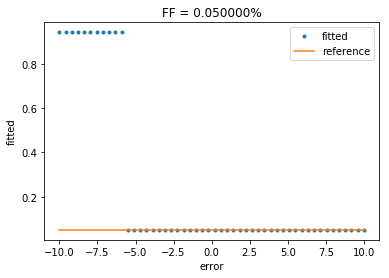

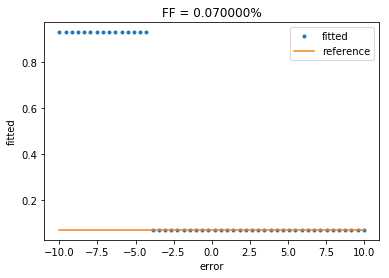

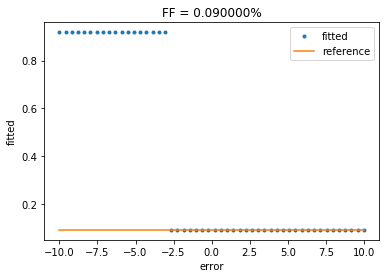

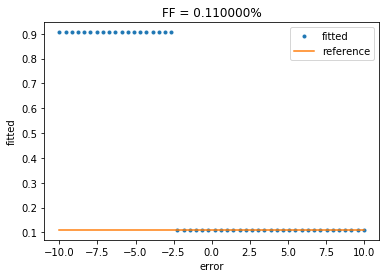

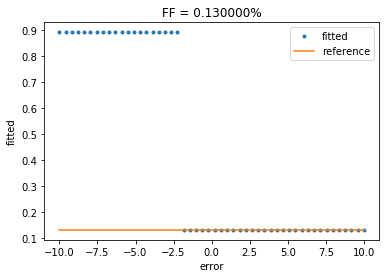

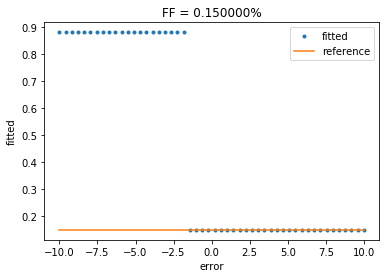

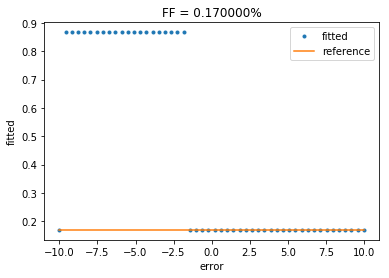

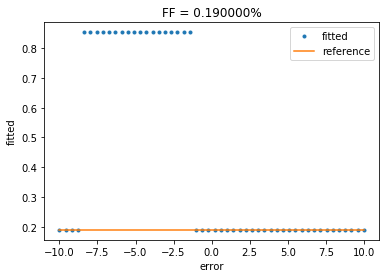

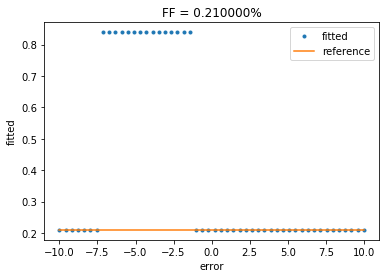

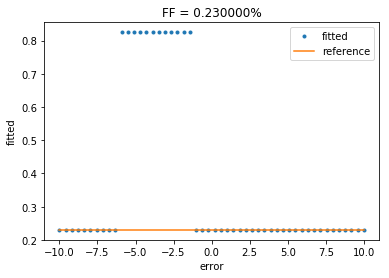

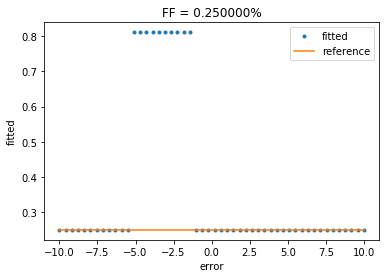

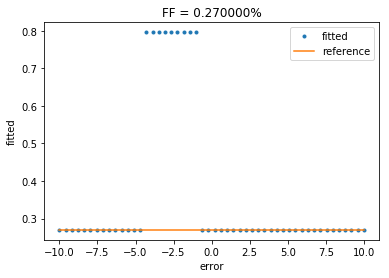

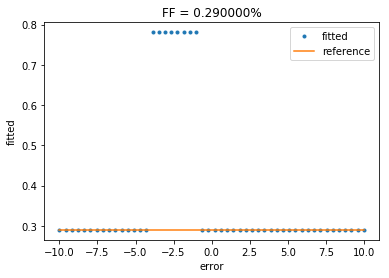

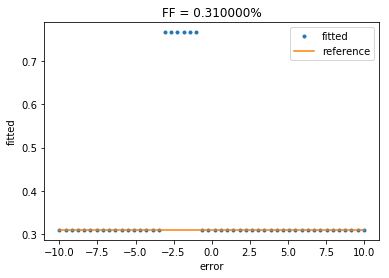

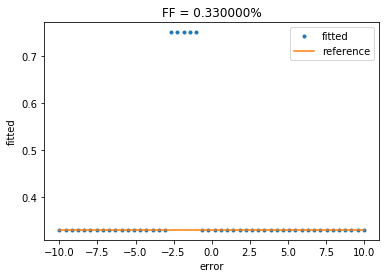

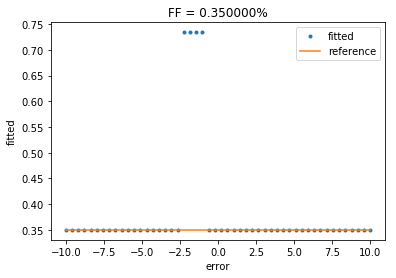

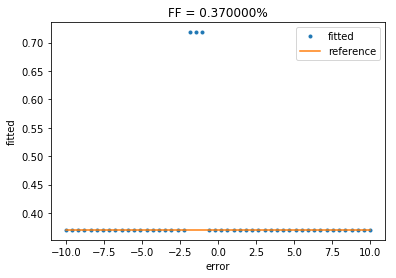

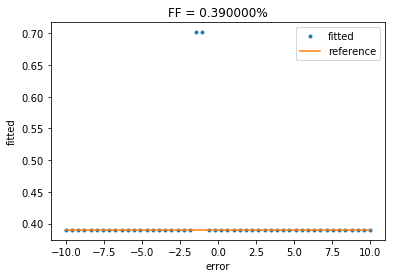

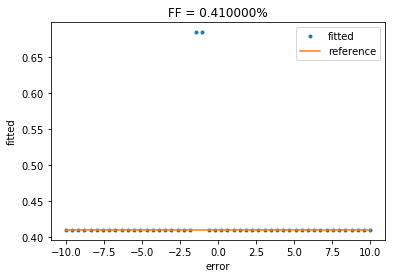

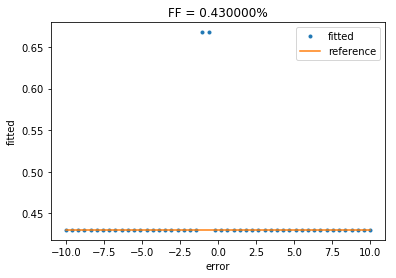

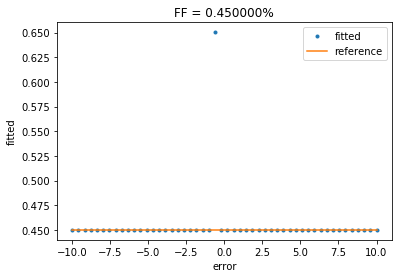

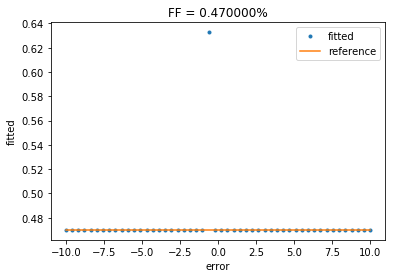

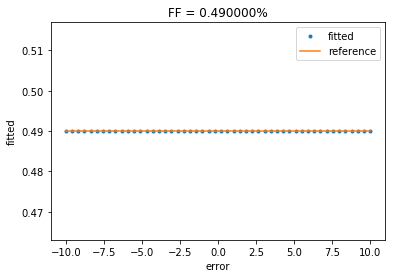

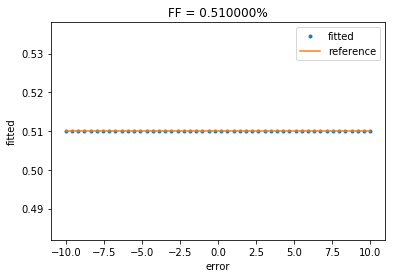

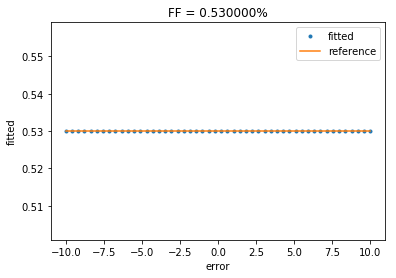

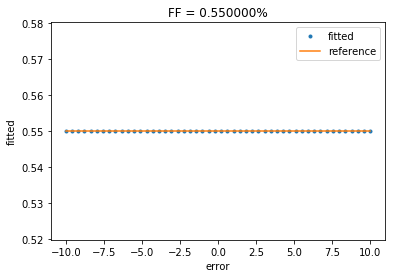

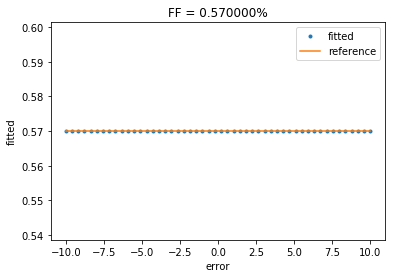

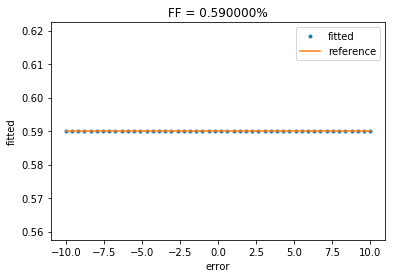

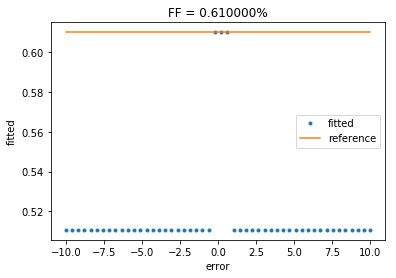

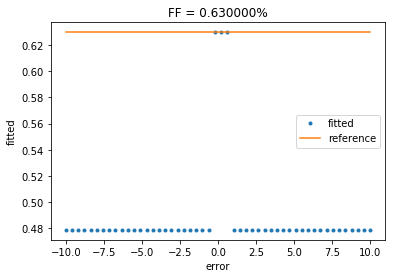

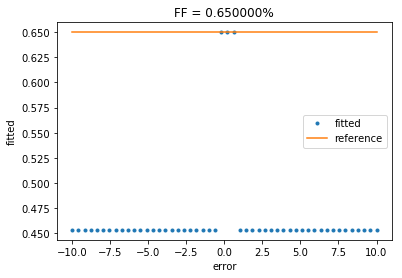

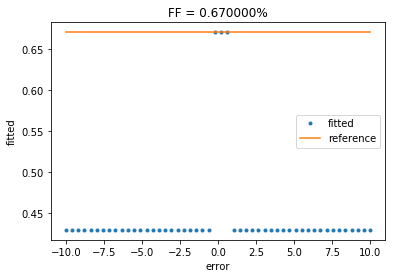

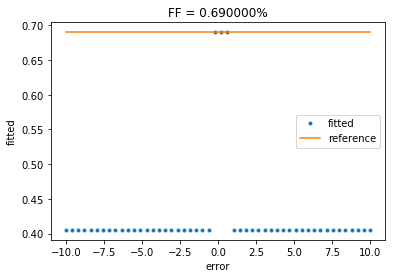

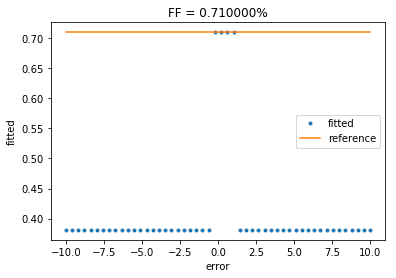

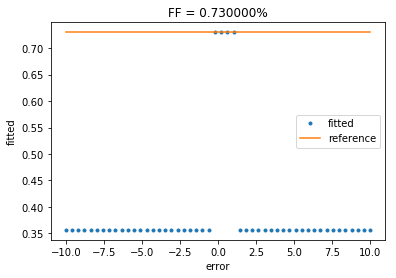

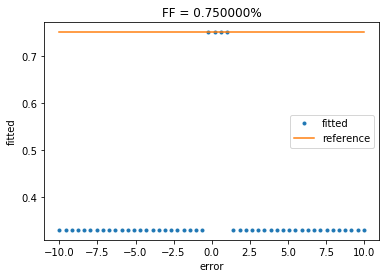

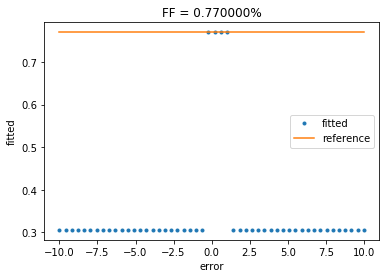

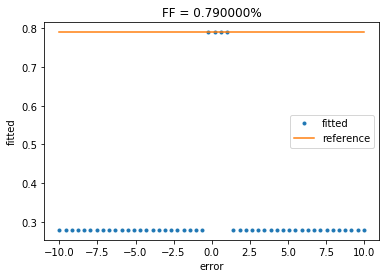

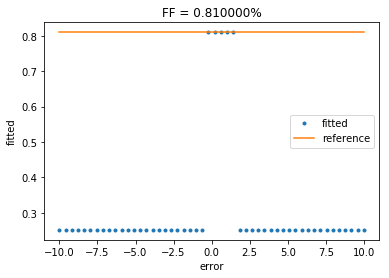

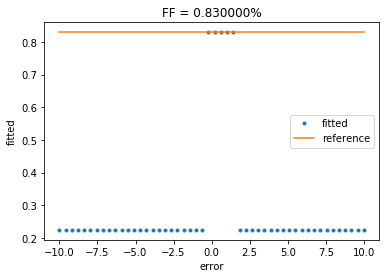

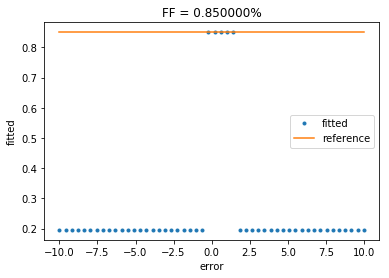

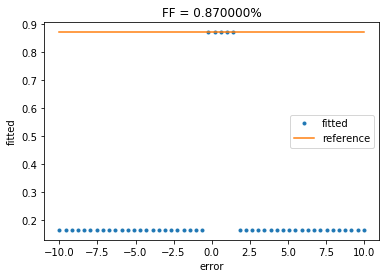

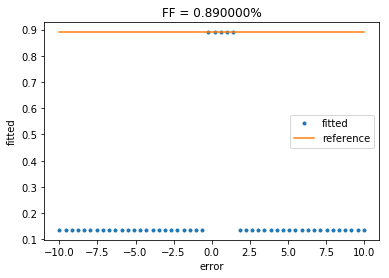

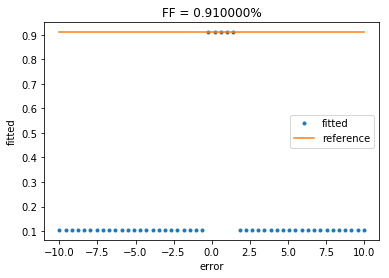

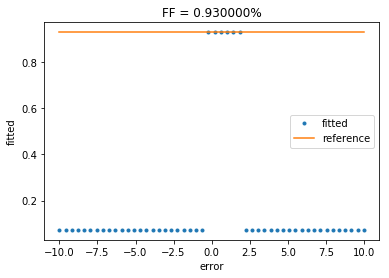

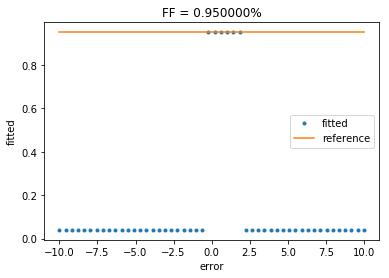

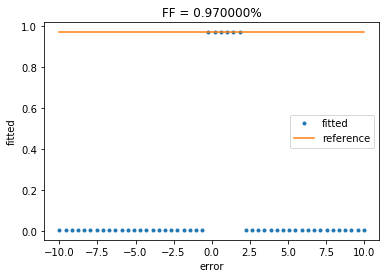

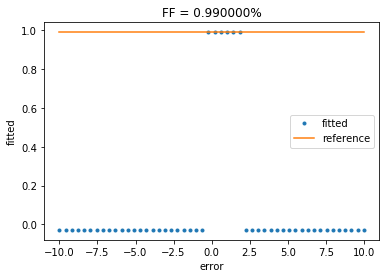

In [64]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.99)   # fat fraction
error = np.linspace(-10,10)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    fitted1 = []
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water+erro] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))
    
    ref = np.zeros(np.size(fitted1))+n #original FF
    
    plt.figure()
    plt.title('FF = %f%%' % n)
    plt.xlabel('error')
    plt.ylabel('fitted')
    plt.plot(error, fitted1,'.', label='fitted')
    plt.plot(error, ref, label='reference')
    plt.legend()
    plt.show

[[ 0.01        0.01        0.01       ...,  0.01        0.01        0.01      ]
 [ 0.03        0.03        0.03       ...,  0.03        0.03        0.95517037]
 [ 0.94318524  0.94318524  0.94318525 ...,  0.94318524  0.94318525
   0.94318524]
 ..., 
 [ 0.95        0.95        0.95       ...,  0.95        0.95        0.95      ]
 [ 0.97        0.97        0.97       ...,  0.97        0.97        0.97      ]
 [ 0.99        0.99        0.99       ...,  0.99        0.99        0.99      ]]
0.91
[ 0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91
  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91
  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91
  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91  0.91
  0.91  0.91]


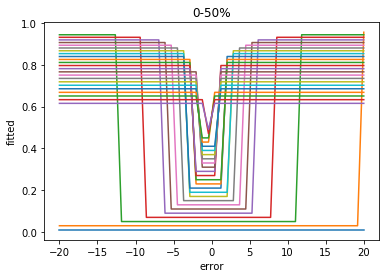

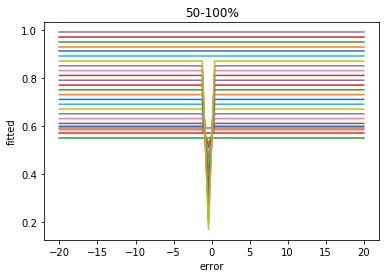

In [24]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.99)   # fat fraction
error = np.linspace(-20,20)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted1 = np.reshape(np.array(fitted1), (np.size(error), np.size(ff)))

plt.figure(1)
plt.xlabel('error')
plt.ylabel('fitted')
for i in range(np.size(fitted1[0])/2):
    plt.title('0-50%')
    plt.plot(error, fitted1[i,:])
plt.show

plt.figure(2)
plt.xlabel('error')
plt.ylabel('fitted')
for i in range(np.size(fitted1[0])/2):
    plt.title('50-100%')
    plt.plot(error, fitted1[(np.size(fitted1[0])/2)+i,:])
plt.show

print ff[45]
print fitted1[45]

# Variando o valor inicial da gordura (absoluto)

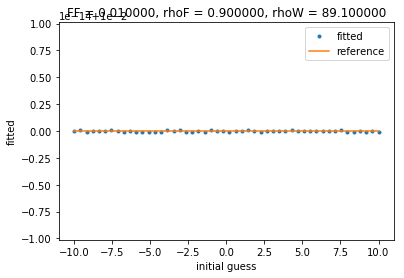

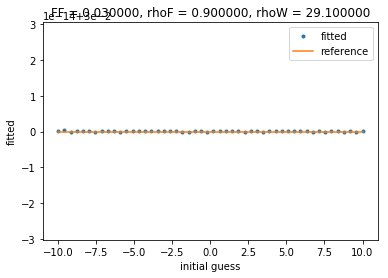

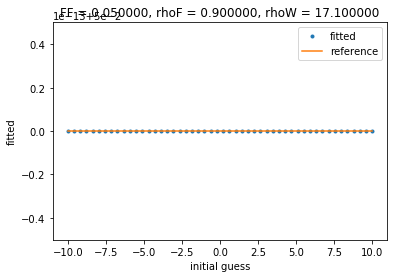

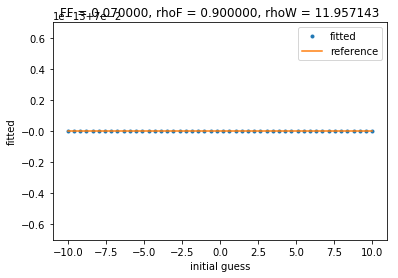

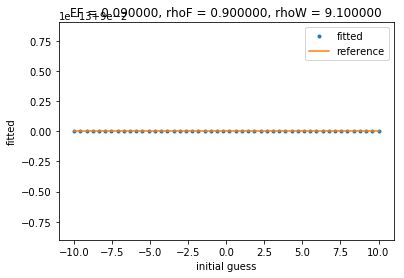

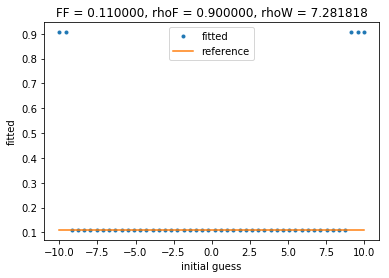

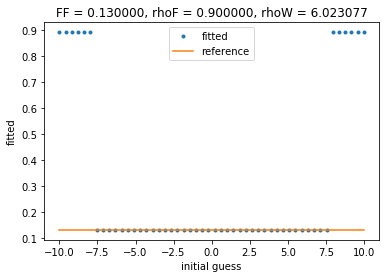

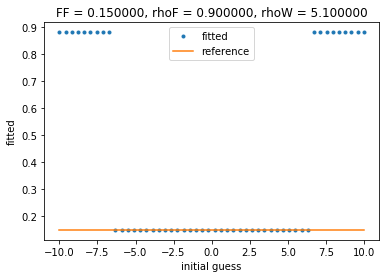

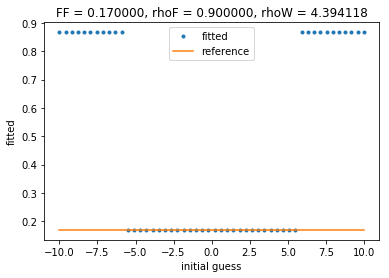

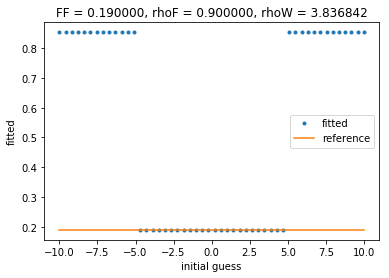

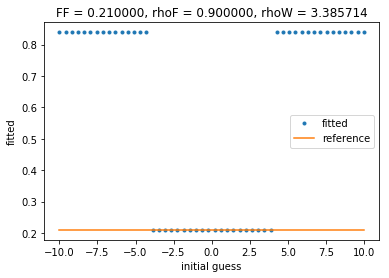

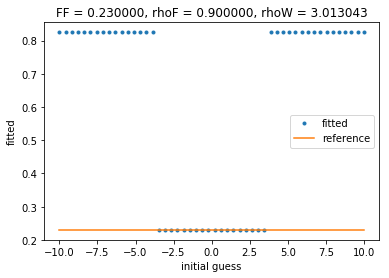

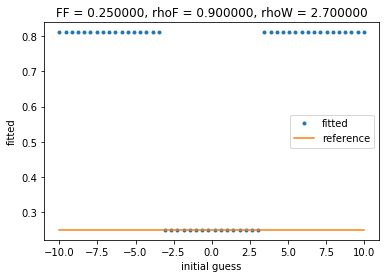

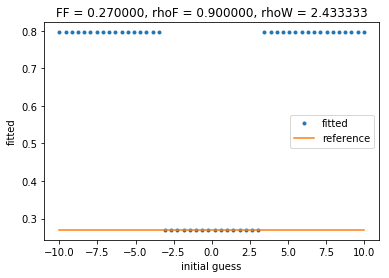

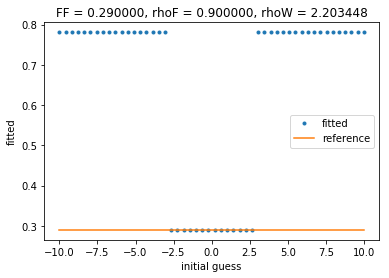

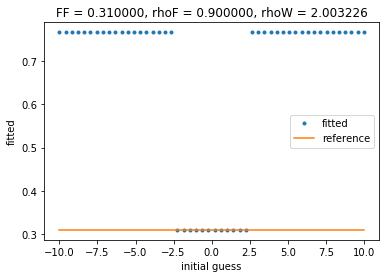

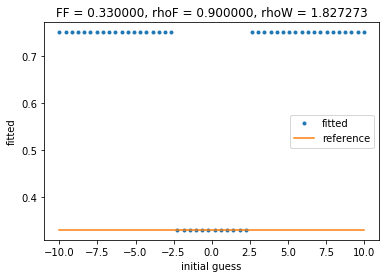

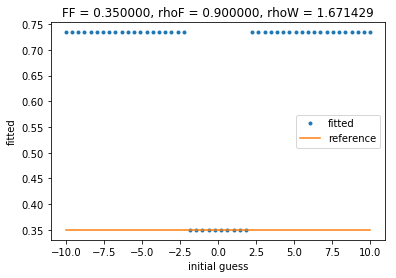

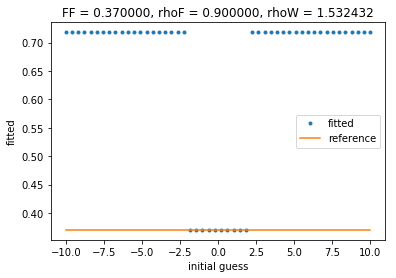

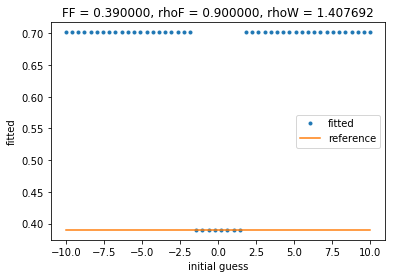

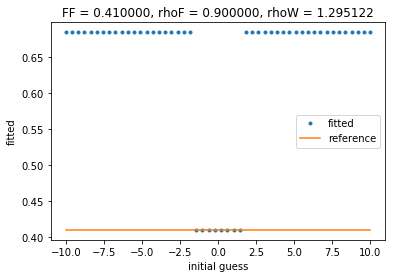

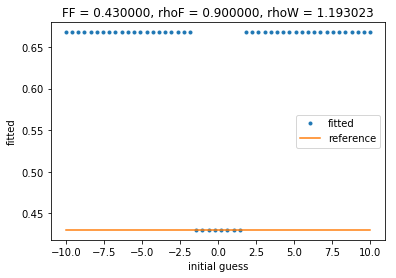

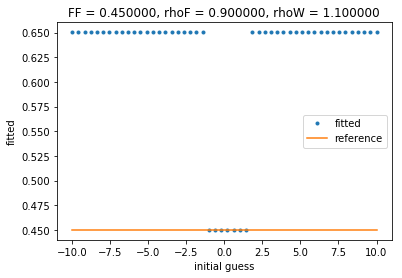

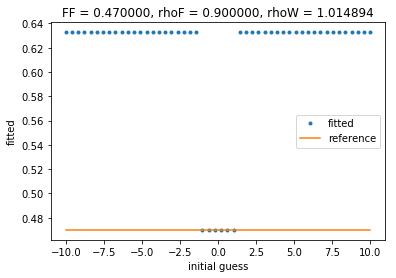

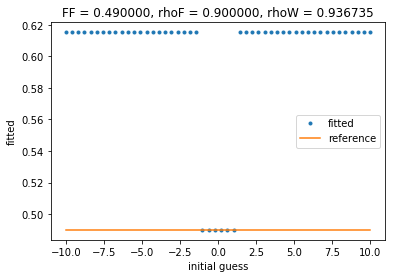

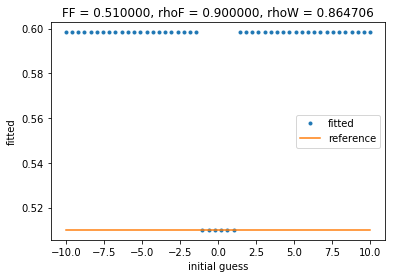

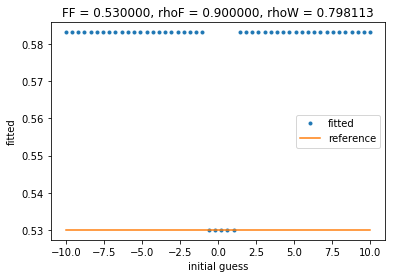

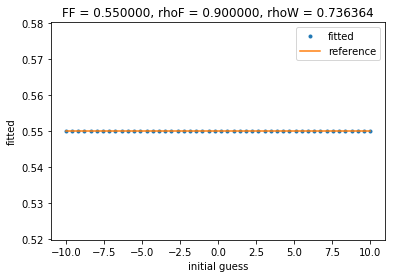

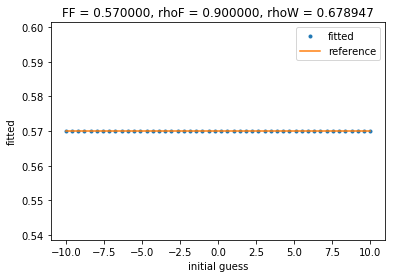

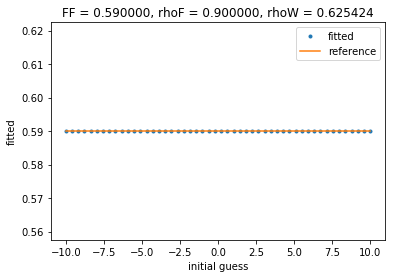

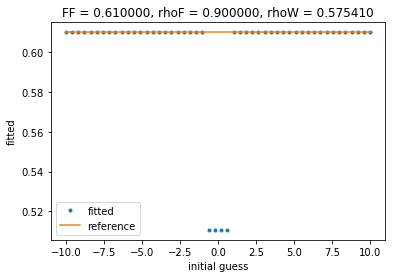

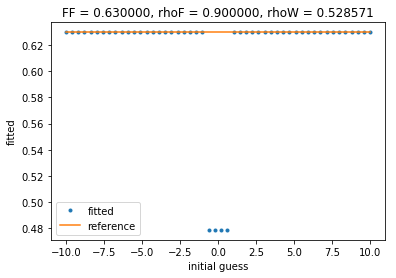

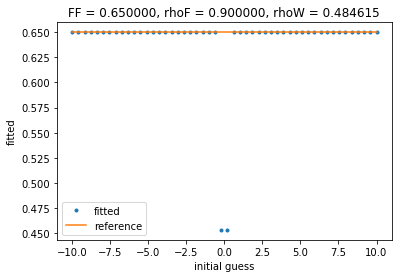

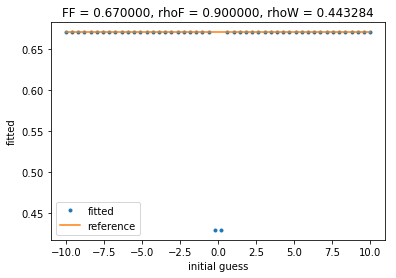

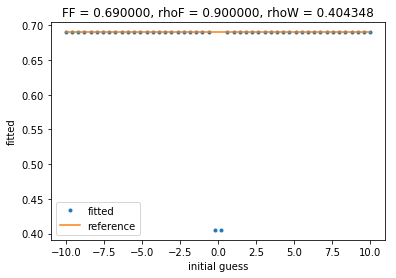

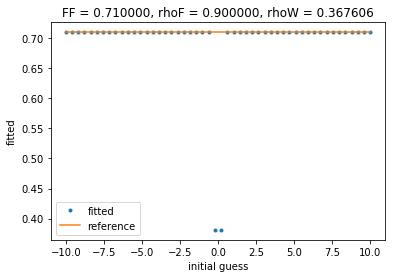

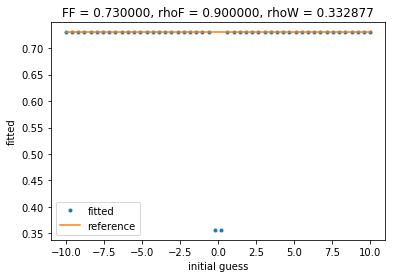

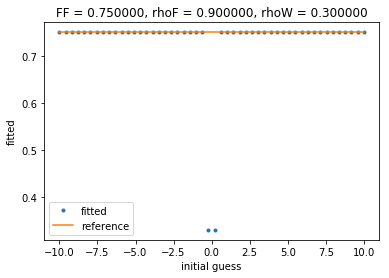

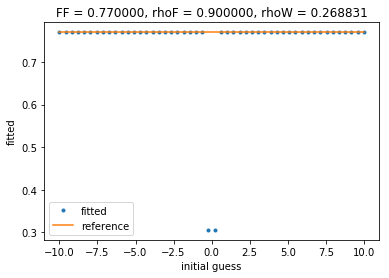

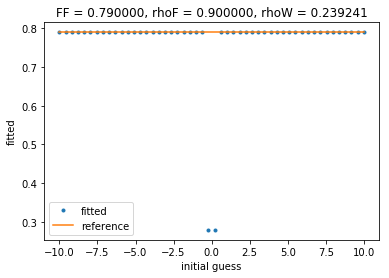

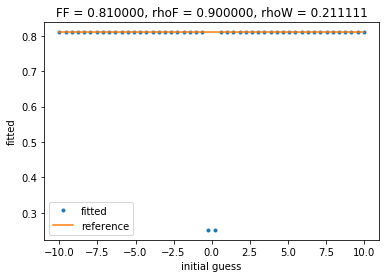

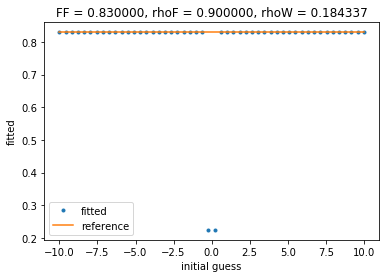

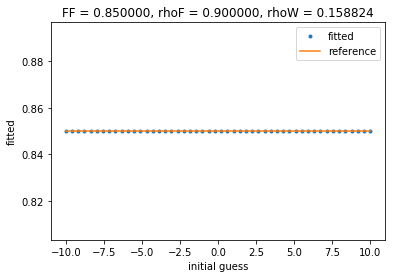

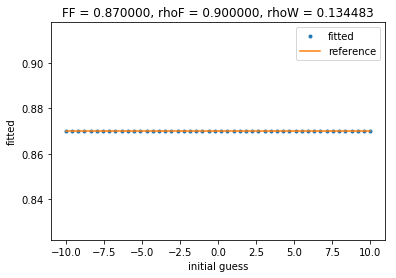

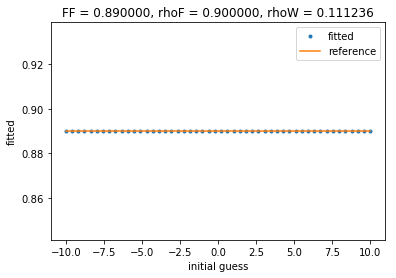

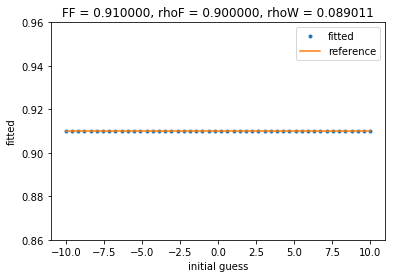

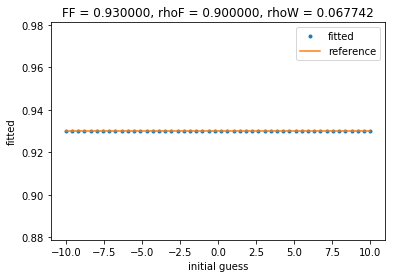

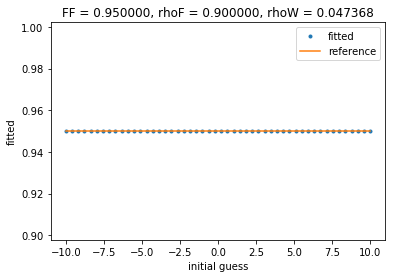

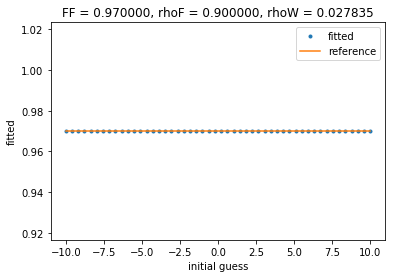

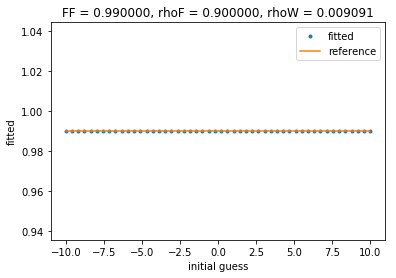

In [26]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.99)   # fat fraction
error = np.linspace(-10,10)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    fitted1 = []
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [erro, rho_water] # ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))
    
    ref = np.zeros(np.size(fitted1))+n #original FF
    
    plt.figure()
    plt.title('FF = %f, rhoF = %f, rhoW = %f' %(n, rho_fat, rho_water))
    plt.xlabel('initial guess')
    plt.ylabel('fitted')
    plt.plot(error, fitted1,'.', label='fitted')
    plt.plot(error, ref, label='reference')
    plt.legend()
    plt.show
    

# Variando o valor inicial da água (absoluto)

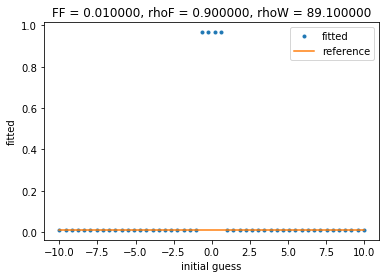

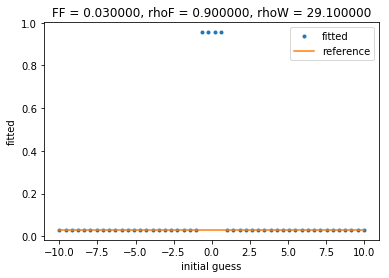

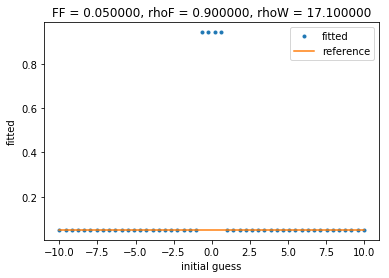

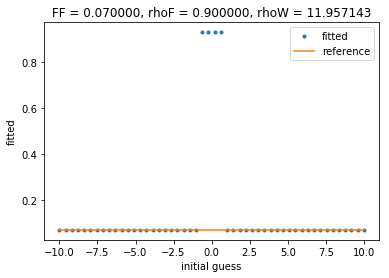

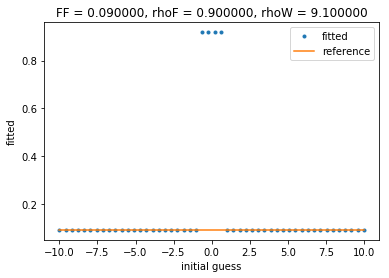

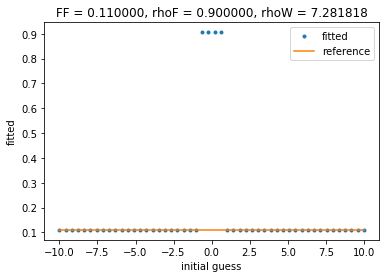

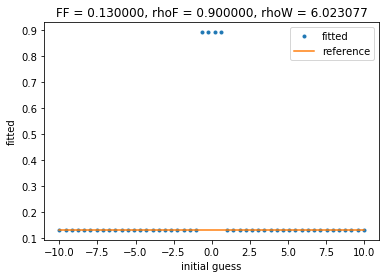

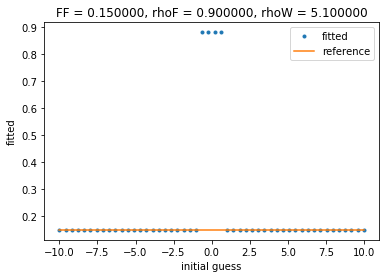

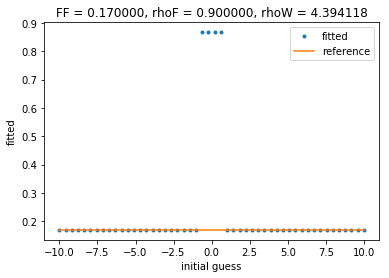

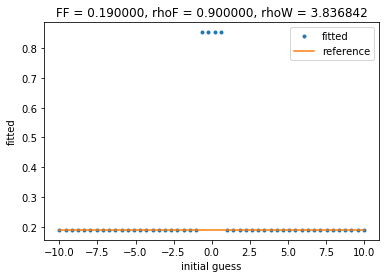

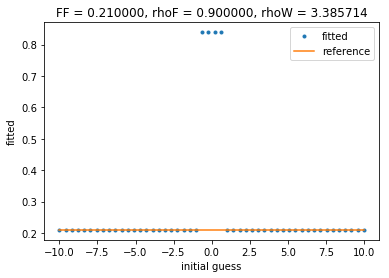

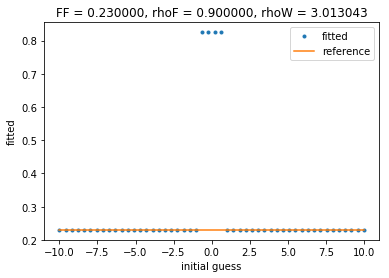

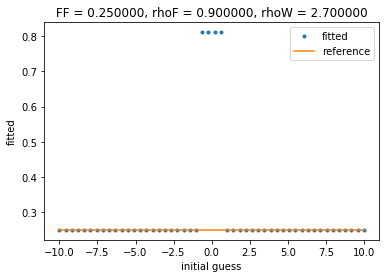

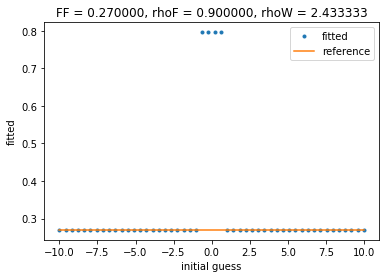

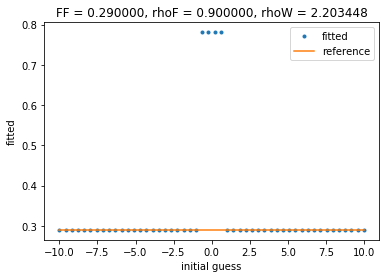

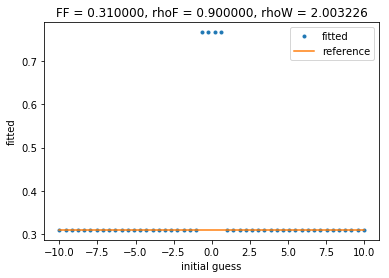

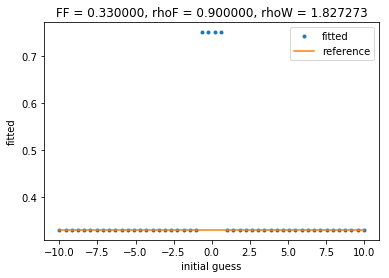

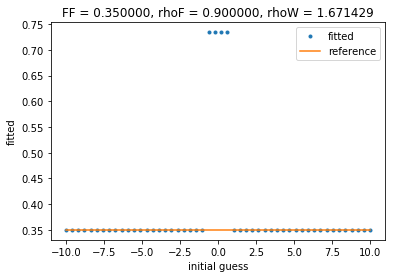

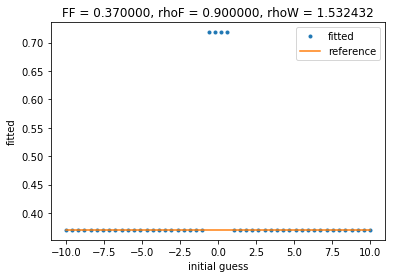

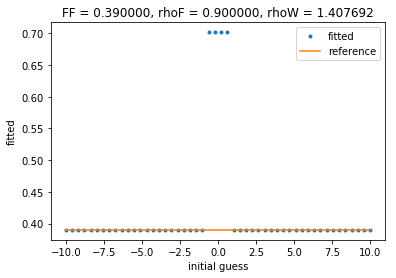

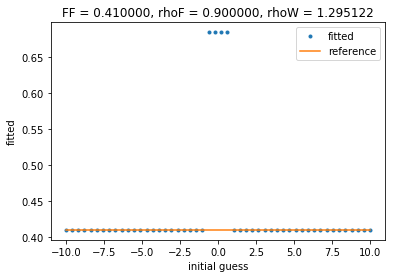

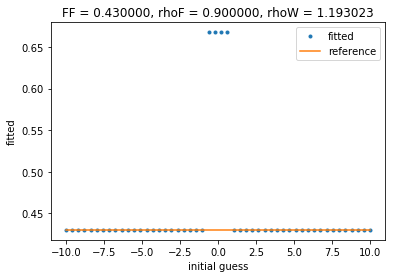

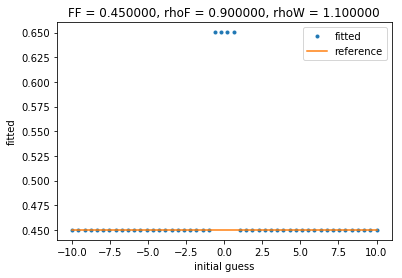

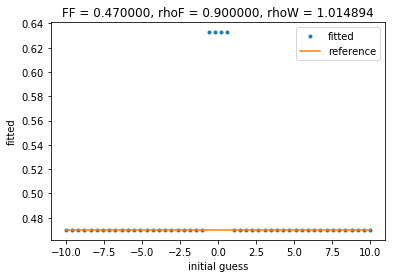

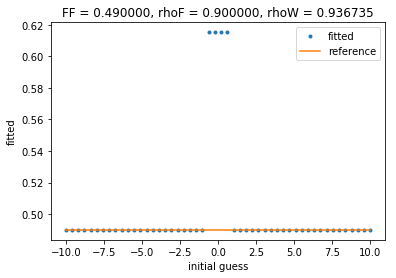

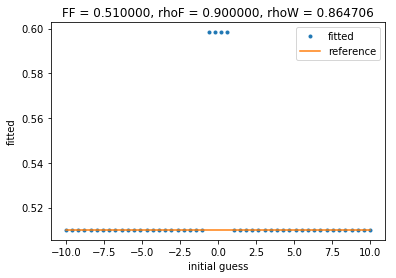

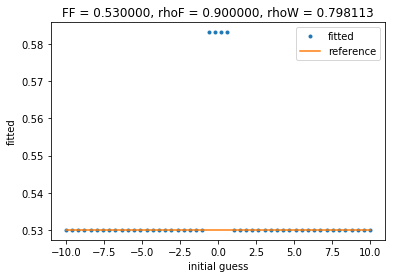

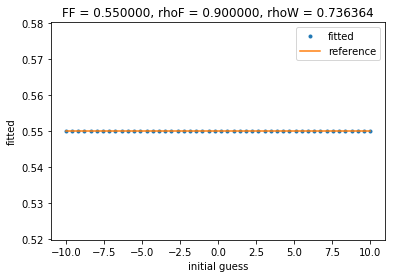

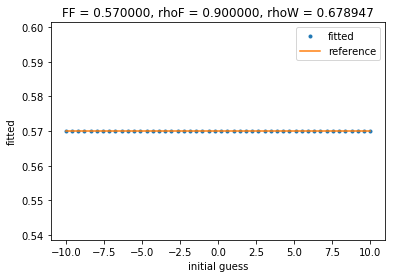

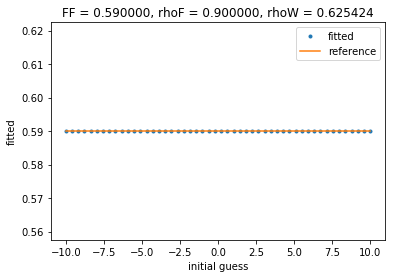

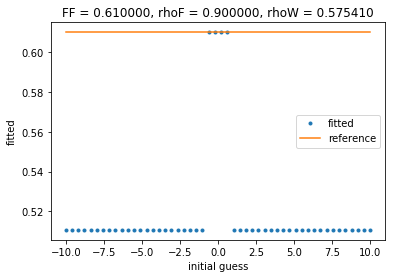

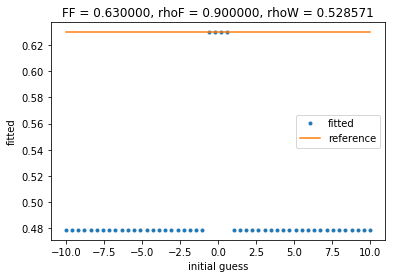

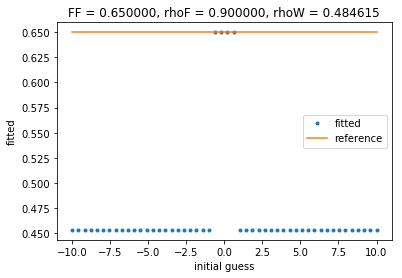

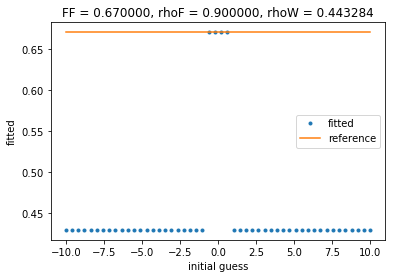

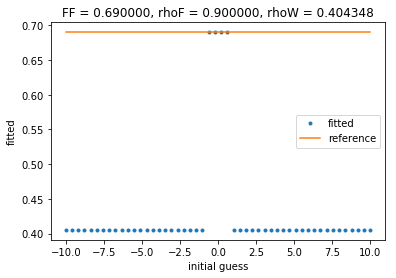

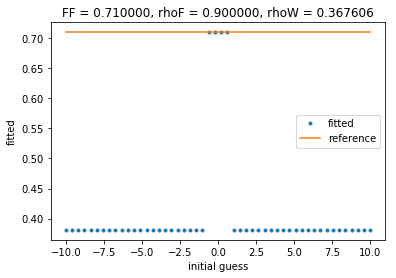

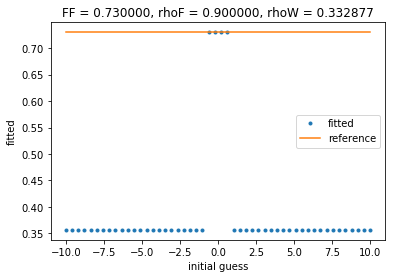

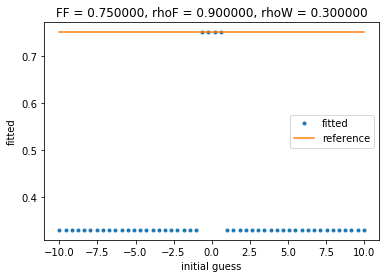

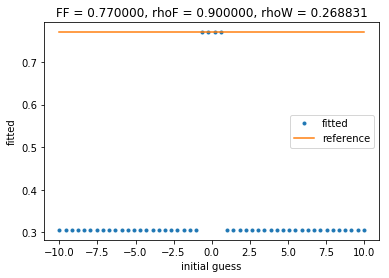

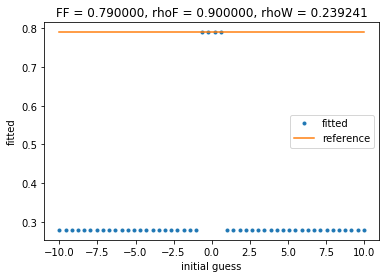

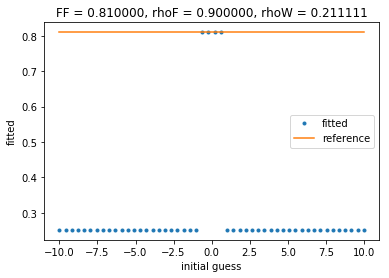

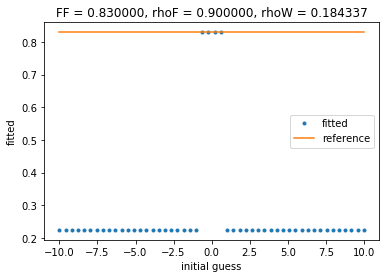

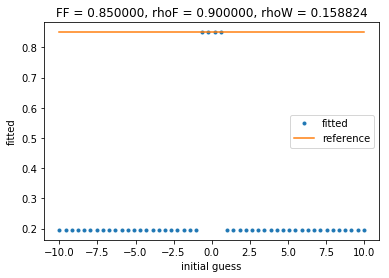

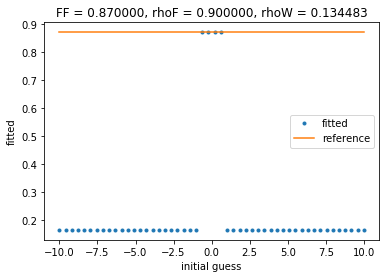

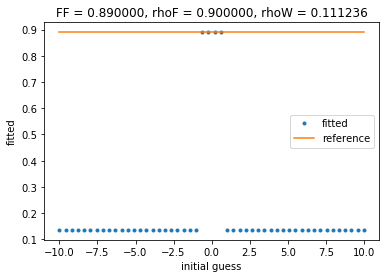

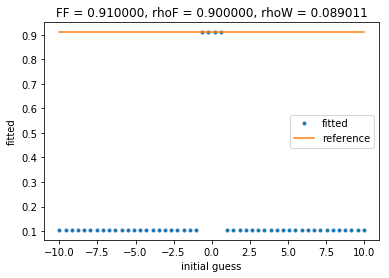

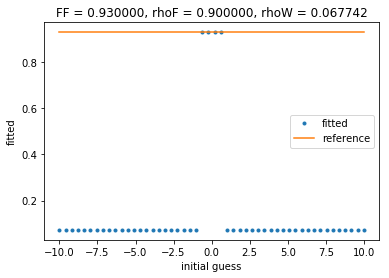

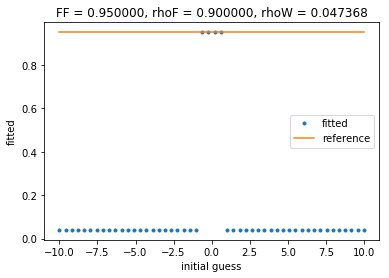

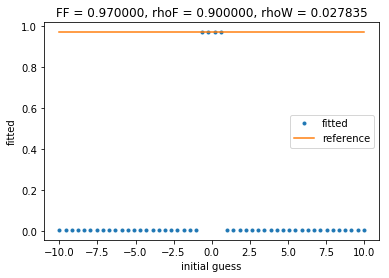

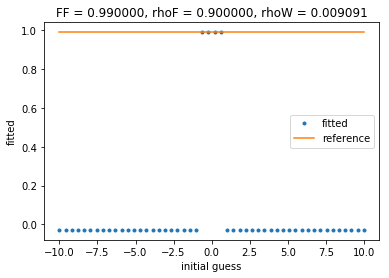

In [27]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.99)   # fat fraction
error = np.linspace(-10,10)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    fitted1 = []
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat, erro] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))
    
    ref = np.zeros(np.size(fitted1))+n #original FF
    
    plt.figure()
    plt.title('FF = %f, rhoF = %f, rhoW = %f' % (n, rho_fat, rho_water))
    plt.xlabel('initial guess')
    plt.ylabel('fitted')
    plt.plot(error, fitted1,'.', label='fitted')
    plt.plot(error, ref, label='reference')
    plt.legend()
    plt.show
    

## Variando o valor da água e da gordura (absolutos)

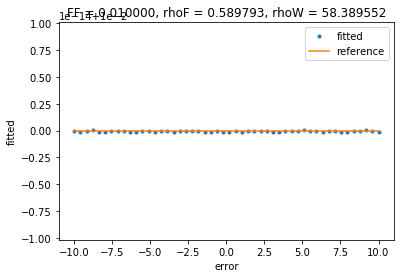

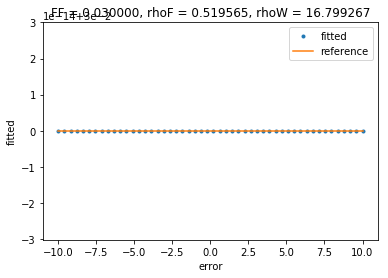

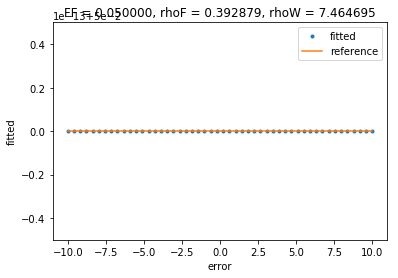

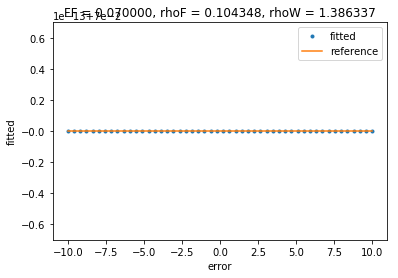

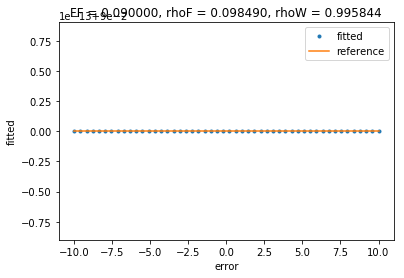

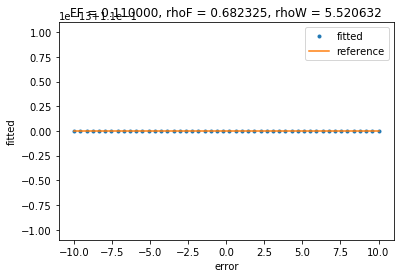

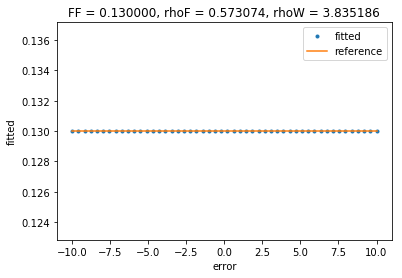

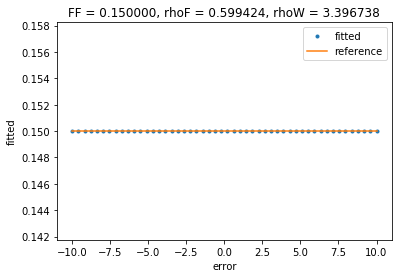

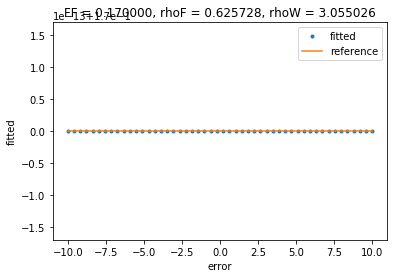

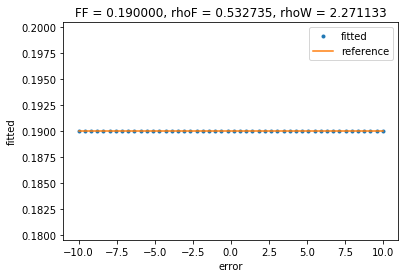

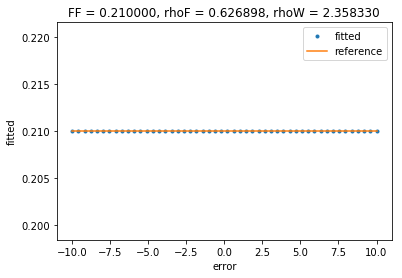

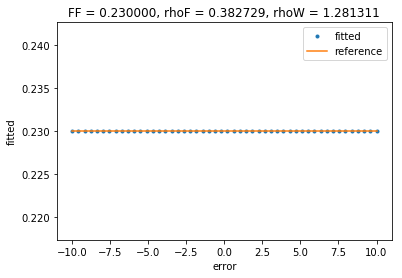

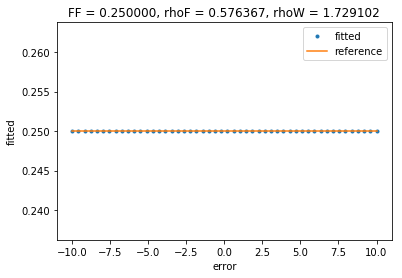

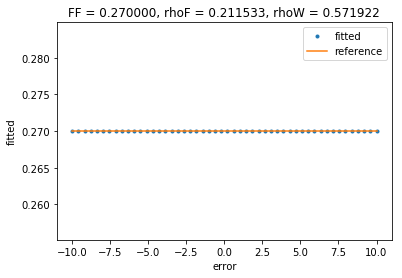

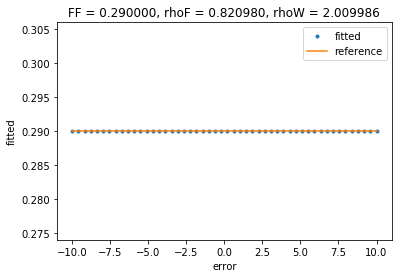

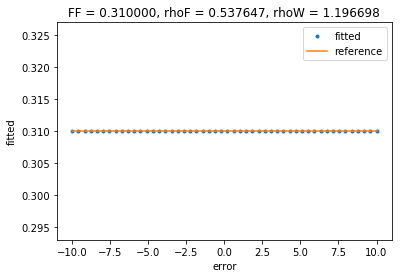

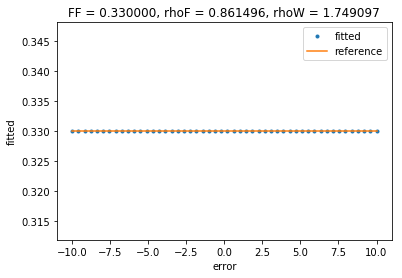

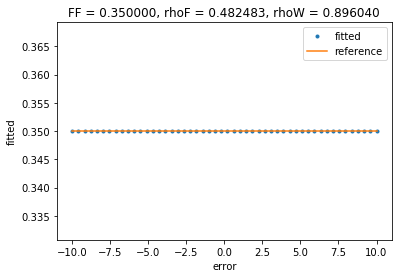

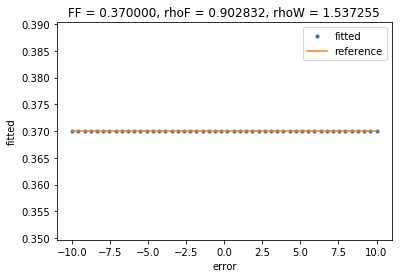

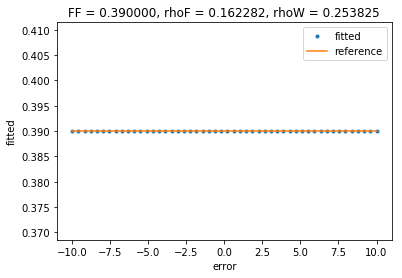

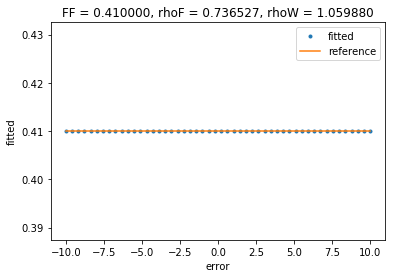

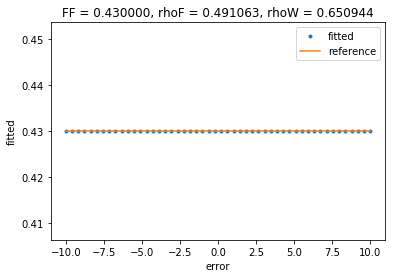

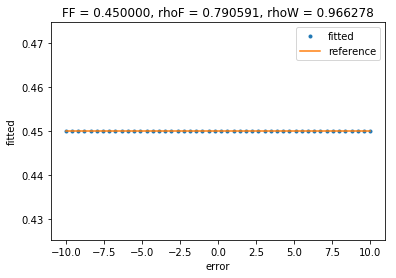

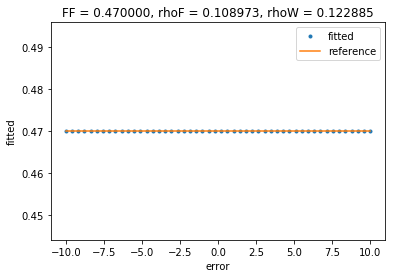

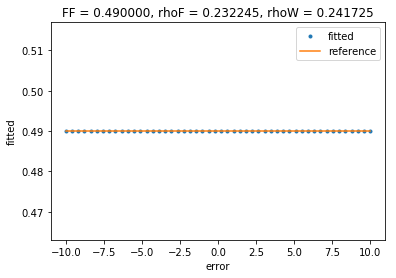

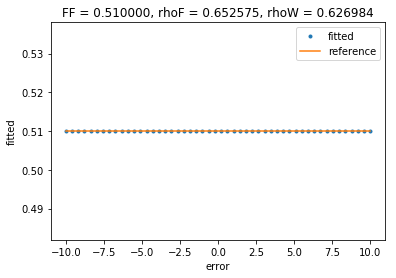

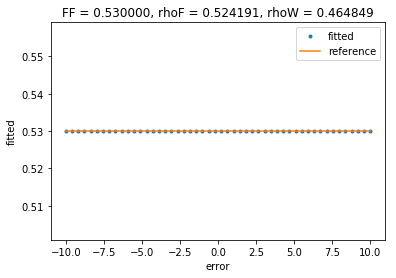

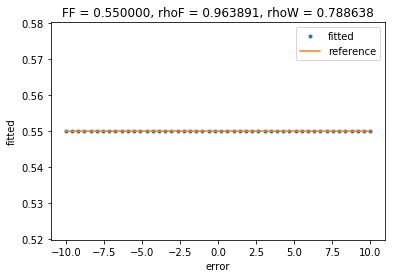

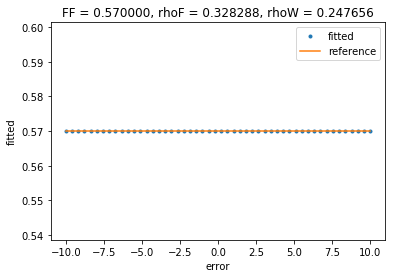

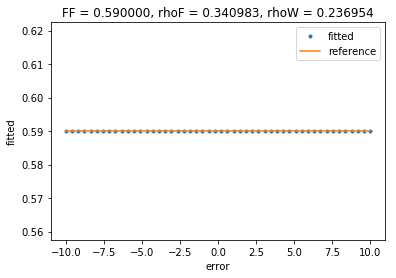

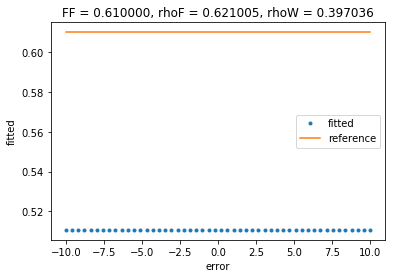

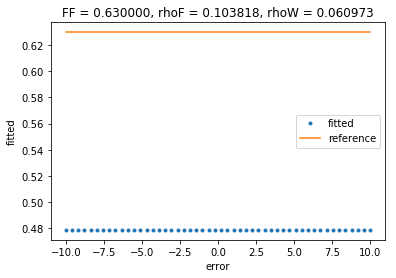

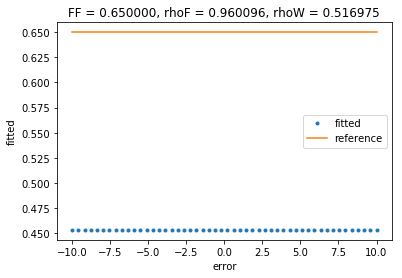

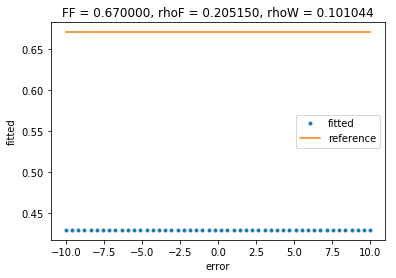

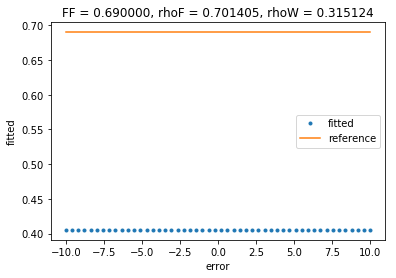

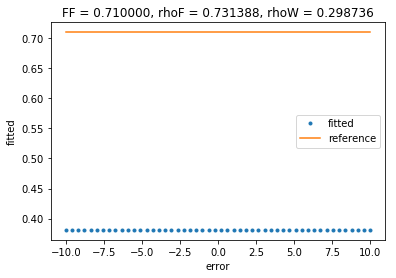

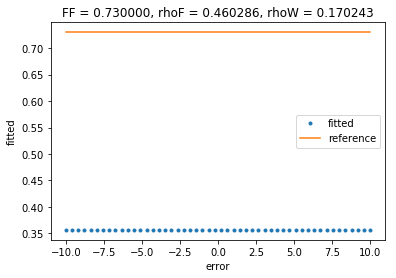

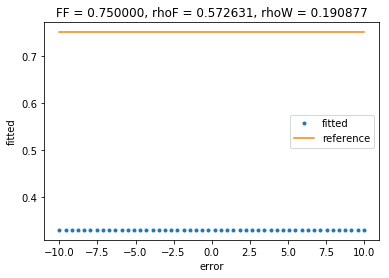

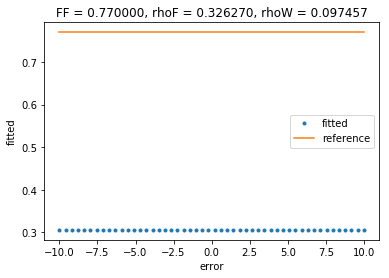

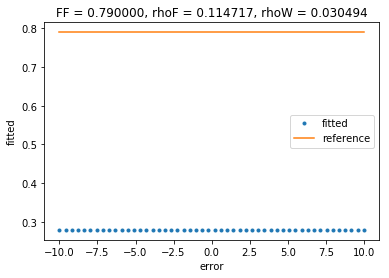

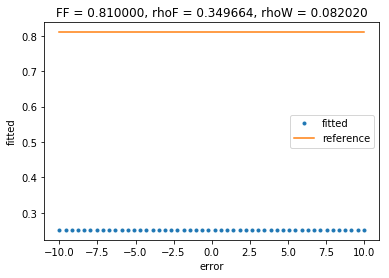

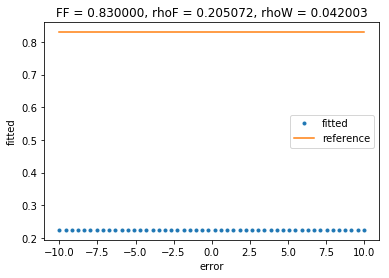

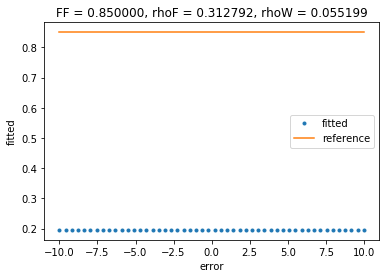

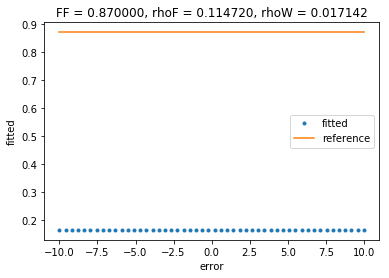

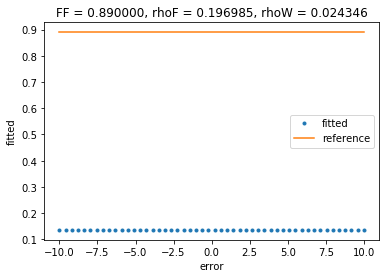

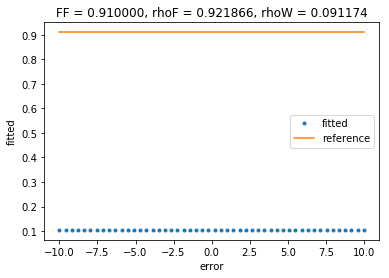

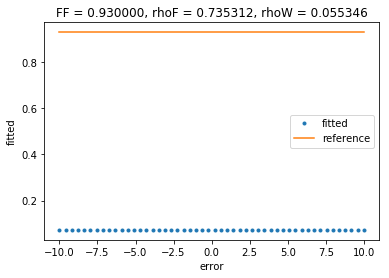

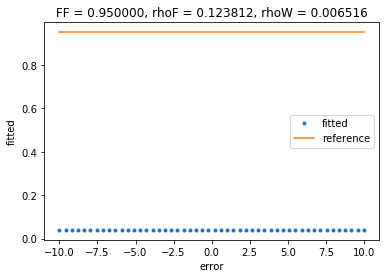

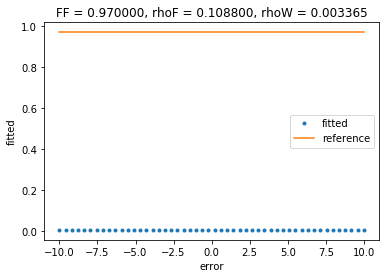

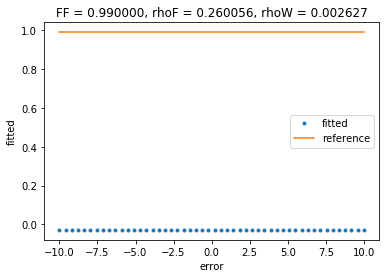

In [22]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.99)   # fat fraction
error = np.linspace(-10,10)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    fitted1 = []
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [erro, erro] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))
    
    ref = np.zeros(np.size(fitted1))+n #original FF
    
    plt.figure()
    plt.title('FF = %f, rhoF = %f, rhoW = %f' % (n, rho_fat, rho_water))
    plt.xlabel('error')
    plt.ylabel('fitted')
    plt.plot(error, fitted1,'.', label='fitted')
    plt.plot(error, ref, label='reference')
    plt.legend()
    plt.show

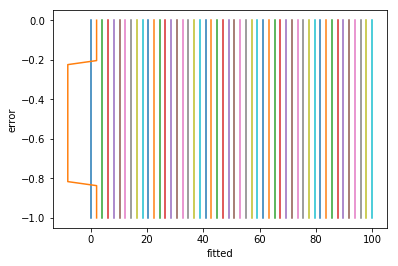

In [3]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,100)   # fat fraction
error = np.linspace(-1,0)    # erro para valores iniciais
fitted_0 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted_0.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted_0 = np.reshape(np.array(fitted_0), (np.size(error), np.size(ff)))

plt.xlabel('fitted')
plt.ylabel('error')
for i in range(np.size(fitted_0[0])):
    plt.plot(fitted_0[i,:],error)

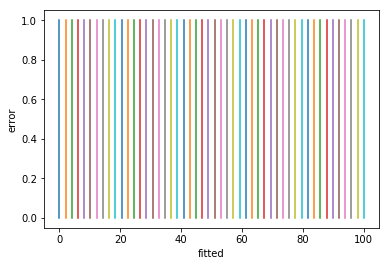

In [4]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,100)   # fat fraction
error = np.linspace(0,1)    # erro para valores iniciais
fitted_01 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted_01.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted_01 = np.reshape(np.array(fitted_01), (np.size(error), np.size(ff)))

plt.xlabel('fitted')
plt.ylabel('error')
for i in range(np.size(fitted_01[0])):
    plt.plot(fitted_01[i,:],error)

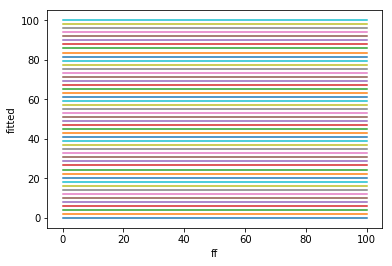

In [8]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,100)   # fat fraction
error = np.zeros(50)    # erro para valores iniciais
fitted_zeros = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted_zeros.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted_zeros = np.reshape(np.array(fitted_zeros), (np.size(error), np.size(ff)))

plt.xlabel('ff')
plt.ylabel('fitted')
for i in range(np.size(fitted_zeros[0])):
    plt.plot(ff, fitted_zeros[i,:])

C:\Users\Yuri\Anaconda2\lib\site-packages\matplotlib\figure.py:402: UserWarning: matplotlib is currently using a non-GUI backend, so cannot show the figure
  "matplotlib is currently using a non-GUI backend, "


('FPS:', 43.706291665937236)


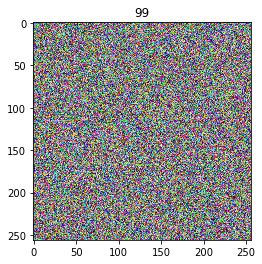